# Childhood Pneumonia Prediction — Comparative ML Framework


## 1. Setup and Imports

In [1]:
!pip install xgboost lightgbm shap imbalanced-learn openpyxl -q


In [2]:
import warnings
warnings.filterwarnings('ignore')

import os
import json
import pickle
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import shap

import sklearn
import imblearn
import xgboost
import lightgbm
import scipy
from scipy import stats
from scipy.stats import randint, uniform, mannwhitneyu, chi2_contingency

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     RandomizedSearchCV, train_test_split)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, brier_score_loss)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

os.makedirs('figs', exist_ok=True)
os.makedirs('results', exist_ok=True)
os.makedirs('cache', exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})

# ---- run settings ----------------------------------------------------------
QUICK = False                     # True = quick smoke test only. FINAL RUN MUST BE False.
SEED = 42
N_BOOT = 200 if QUICK else 2000   # bootstrap replications for AUC confidence intervals

VERSIONS = {
    'python': sys.version.split()[0],
    'platform': platform.platform(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scipy': scipy.__version__,
    'sklearn': sklearn.__version__,
    'imblearn': imblearn.__version__,
    'xgboost': xgboost.__version__,
    'lightgbm': lightgbm.__version__,
    'shap': shap.__version__,
}
print(VERSIONS)


{'python': '3.13.15', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'imblearn': '0.14.2', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'shap': '0.52.0'}


**Helper functions.**

In [3]:
def bootstrap_auc_ci(y_true, y_prob, n_boot=None, seed=SEED):
    """Stratified percentile bootstrap 95% CI for AUC."""
    if n_boot is None:
        n_boot = N_BOOT
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    pos = np.where(y_true == 1)[0]
    neg = np.where(y_true == 0)[0]
    if len(pos) < 2 or len(neg) < 2:
        return (np.nan, np.nan)

    aucs = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        aucs.append(roc_auc_score(y_true[idx], y_prob[idx]))
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    return (lo, hi)


def cv_summary(scores):
    """Mean, SD and t-based 95% CI of the mean over CV folds."""
    s = np.asarray(scores, dtype=float)
    k = len(s)
    sd = s.std(ddof=1)
    half = stats.t.ppf(0.975, k - 1) * sd / np.sqrt(k)
    return {'mean': s.mean(), 'sd': sd,
            'ci_low': s.mean() - half, 'ci_high': s.mean() + half, 'half': half}


def save(df, name):
    df.to_csv('results/' + name + '.csv', index=False)
    return df


# ---- resumable cache: expensive steps are saved to disk --------------------
def cached(key, fn):
    """Run fn() once and cache the result in cache/<key>.pkl."""
    path = 'cache/' + key + '.pkl'
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return pickle.load(f)
    result = fn()
    with open(path + '.tmp', 'wb') as f:      # write to temp file first,
        pickle.dump(result, f)                # so a killed run never leaves
    os.replace(path + '.tmp', path)           # a corrupt cache file
    return result


def nested_scores(key, search, X_tr, y_tr, outer):
    """Nested CV: repeat the whole hyperparameter search inside each outer fold."""
    scores = []
    for k, (tr, va) in enumerate(outer.split(X_tr, y_tr)):
        def run_one(tr=tr, va=va):
            m = clone(search).fit(X_tr.iloc[tr], y_tr[tr])
            return roc_auc_score(y_tr[va], m.predict_proba(X_tr.iloc[va])[:, 1])
        scores.append(cached('nest_' + key + '_fold' + str(k), run_one))
    return np.array(scores)


## 2. Load Data and Engineer Features

We load the raw clinical dataset and build the target variable plus 28 predictive features: clinical biomarkers, demographics, socio-environmental determinants, and vaccination history.

In [4]:
DATA_PATH = os.environ.get('BD_IRA_PATH', '/content/BD_IRA.xlsx')   # set BD_IRA_PATH or edit
df = pd.read_excel(DATA_PATH)
print('Raw shape:', df.shape)
df.head()


Raw shape: (801, 91)


,ID PATIENT,Admission date,Age (months),Gender,Medical insurance,Length of stay (Days),Meets criteria for clinical pneumonia,Number of persons living in house,Number of siblings,Number of rooms in house,...,HIV testing,HIV test results,Blood culture results,Nasopharyngeal aspirate culture (NPA) Identification 1,Nasopharyngeal aspirate culture (NPA) Identification 2,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 1,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 2,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 3,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 4,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 5
0,PN0001,2010-11-02,41,Male,No,57,Yes,5.0,3.0,1.0,...,No,NaN,Negative,Negative,NaN,Rhinovirus,N/A,N/A,N/A,N/A
1,PN0002,2010-11-02,56,Female,No,3,Yes,6.0,4.0,2.0,...,No,NaN,Negative,Negative,NaN,Parainfluenza viruses 3,Parainfluenza viruses 1,Adenovirus,Rhinovirus,N/A
2,PN0003,2010-11-03,26,Male,Yes,12,Yes,6.0,4.0,2.0,...,No,NaN,Negative,Negative,NaN,CoronavirusesNL63,NaN,N/A,N/A,N/A
3,PN0004,2010-11-04,2,Male,No,22,Yes,7.0,4.0,1.0,...,No,NaN,Pseudomonas oryzihabitans,Negative,NaN,RSV-B,Parainfluenza viruses 3,Rhinovirus,N/A,N/A
4,PN0005,2010-11-05,15,Male,No,7,Yes,5.0,3.0,2.0,...,No,NaN,Negative,Negative,NaN,Adenovirus,NaN,N/A,N/A,N/A


**Target variable: pneumonia-positive diagnoses.**

In [5]:
pneumonia_diags = ['Pneumonia', 'Dyspneic pneumopathy', 'Staphylococcal pneumonia',
                   'Bronchiolitis + Pneumonia', 'Asthma attack + Pneumonia',
                   'Pleuropneumonitis', 'Interstitial pneumopathy']

df['target'] = df['Main diagnostic '].isin(pneumonia_diags).astype(int)

print(df['target'].value_counts())
print(f'Positive (pneumonia) rate: {df["target"].mean():.1%}')


target
0    582
1    219
Name: count, dtype: int64
Positive (pneumonia) rate: 27.3%


**Feature engineering.**

In [6]:
def yn(col):
    # Yes -> 1, No -> 0. A MISSING answer stays NaN (imputed later in the pipeline),
    # instead of being silently coded as 'No'.
    s = df[col].str.strip().str.lower()
    return (s == 'yes').astype(float).where(s.notna(), np.nan)


feat = pd.DataFrame()

# --- Clinical biomarkers ---
feat['CRP']             = pd.to_numeric(df['C-reactive protein'], errors='coerce')
feat['Procalcitonin']   = pd.to_numeric(df['Procalcitonin'], errors='coerce')
feat['SaO2']            = pd.to_numeric(df['Oxygen saturation (SaO2) at admission'], errors='coerce')
feat['Temperature']     = pd.to_numeric(df['Axillary temperature (°C)'], errors='coerce')
feat['RespiratoryRate'] = pd.to_numeric(df['Respiratory rate'], errors='coerce')
feat['HeartRate']       = pd.to_numeric(df['Heart rate'], errors='coerce')

# --- Clinical signs ---
feat['Fever']        = yn('History of fever')
feat['Crackles']     = yn('Crackles')
feat['Wheezing']     = yn('Wheezing')
feat['NasalFlaring'] = yn('Nasal flaring')
feat['Cyanosis']     = yn('Cyanosis')

# --- Demographic ---
feat['Age']          = df['Age (months)'].astype(float)
feat['Gender']       = (df['Gender '].str.strip() == 'Male').astype(int)
feat['Siblings']     = pd.to_numeric(df['Number of siblings'], errors='coerce')
feat['Prematurity']  = yn('Health history : Prematurity                      ')
feat['Breastfed']    = yn('Breastfeeding')
feat['PriorRespAdm'] = yn('Health history : Prior admission because of respiratory condition')

# --- Socio-environmental ---
feat['HouseholdSize']  = pd.to_numeric(df['Number of persons living in house'], errors='coerce')
feat['Rooms']          = pd.to_numeric(df['Number of rooms in house'], errors='coerce')
feat['PersonsPerRoom'] = feat['HouseholdSize'] / feat['Rooms'].replace(0, np.nan)
feat['SmokersAtHome']  = yn('Smokers at home')
feat['VitaminA']       = yn('Vitamin A supplementation ')

# --- Vaccination (one-hot + dose counts) ---
vax = df['Age-appropriate vaccinations'].str.strip()
feat['Vacc_Full']    = (vax == 'Yes').astype(float).where(vax.notna(), np.nan)
feat['Vacc_Partial'] = (vax == 'Partially').astype(float).where(vax.notna(), np.nan)
feat['Vacc_None']    = (vax == 'No').astype(float).where(vax.notna(), np.nan)
feat['HibDoses']     = pd.to_numeric(df['Number of Hib vaccine doses received'], errors='coerce')
feat['PneumoDoses']  = pd.to_numeric(df['Number of pneumococcal vaccine doses received'], errors='coerce')

# --- Chest X-ray (ordinal encode) ---
xray_map = {'Normal': 0, 'NF': 1, 'Other infiltrates': 2, 'Endpoint pneumonia': 3}
# NOTE: the raw column contains 'Other infiltrates ' WITH A TRAILING SPACE; without
# .str.strip() those 62 records silently became NaN. The column has no truly missing values.
feat['ChestXray'] = df['Chest X-ray finding'].str.strip().map(xray_map)
assert feat['ChestXray'].notna().all(), 'unmapped chest X-ray category'

feat['target'] = df['target'].values

print(f'Engineered {feat.shape[1] - 1} features.')
feat.head()


Engineered 28 features.


,CRP,Procalcitonin,SaO2,Temperature,RespiratoryRate,HeartRate,Fever,Crackles,Wheezing,NasalFlaring,...,PersonsPerRoom,SmokersAtHome,VitaminA,Vacc_Full,Vacc_Partial,Vacc_None,HibDoses,PneumoDoses,ChestXray,target
0,79.0,1.35,80.0,37.8,72.0,143.0,1.0,0.0,0.0,1.0,...,5.0,1.0,1.0,1.0,0.0,0.0,3,0,3,1
1,46.0,0.10,91.0,38.0,84.0,142.0,1.0,0.0,1.0,1.0,...,3.0,1.0,1.0,1.0,0.0,0.0,3,0,1,0
2,4.0,0.10,99.0,37.6,60.0,130.0,0.0,0.0,1.0,1.0,...,3.0,1.0,1.0,1.0,0.0,0.0,3,1,2,0
3,5.0,0.06,84.0,36.8,90.0,135.0,0.0,0.0,1.0,0.0,...,7.0,1.0,0.0,0.0,1.0,0.0,1,0,3,0
4,2.0,0.09,93.0,38.5,60.0,144.0,1.0,0.0,1.0,0.0,...,2.5,0.0,1.0,1.0,0.0,0.0,3,0,0,0


**Exclusion of records with missing critical values.** Imputation of everything else happens INSIDE the pipelines.

In [7]:
CRITICAL = ['CRP', 'Age', 'RespiratoryRate', 'HouseholdSize']
FEATURE_COLS = [c for c in feat.columns if c != 'target']

miss = pd.DataFrame({
    'n_missing': feat[FEATURE_COLS].isna().sum(),
    'pct_missing': (feat[FEATURE_COLS].isna().mean() * 100).round(2),
}).reset_index().rename(columns={'index': 'feature'})
save(miss, 'table_missing_data_before_exclusion')

n_before = len(feat)
feat = feat.dropna(subset=CRITICAL + ['target']).copy()
X = feat[FEATURE_COLS].copy()     # DataFrame, original index kept
y = feat['target'].values

print(f'Records: {n_before} -> {len(feat)} (excluded {n_before - len(feat)} missing {CRITICAL})')
print(f'Features: {len(FEATURE_COLS)} | class counts: {dict(feat["target"].value_counts())} '
      f'| positive rate {feat["target"].mean():.3f}')
print('Predictor cells still missing (imputed in-pipeline):', int(X.isna().sum().sum()))


Records: 801 -> 799 (excluded 2 missing ['CRP', 'Age', 'RespiratoryRate', 'HouseholdSize'])
Features: 28 | class counts: {0: np.int64(581), 1: np.int64(218)} | positive rate 0.273
Predictor cells still missing (imputed in-pipeline): 86


## 3. Train-Test Split

One stratified 80/20 split (seed 42). Imputation, scaling and SMOTE are fitted inside pipelines on training data only; the test set is used once for final evaluation.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

SPLIT = {'n_train': len(y_train), 'n_test': len(y_test),
         'train_pos': int(y_train.sum()), 'train_neg': int((y_train == 0).sum()),
         'test_pos': int(y_test.sum()), 'test_neg': int((y_test == 0).sum())}
print(SPLIT)
save(pd.DataFrame([SPLIT]), 'table_split_counts')


{'n_train': 639, 'n_test': 160, 'train_pos': 174, 'train_neg': 465, 'test_pos': 44, 'test_neg': 116}


,n_train,n_test,train_pos,train_neg,test_pos,test_neg
0,639,160,174,465,44,116


## 4. Hyperparameter Tuning

XGBoost, LightGBM, Logistic Regression and Random Forest are tuned with `RandomizedSearchCV` (ROC-AUC, 5-fold stratified CV). Pipeline: median imputation → StandardScaler → SMOTE → classifier, so every step is fitted inside each training fold.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)              # tuning folds
cv_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)  # reporting folds


def make_pipe(clf):
    return ImbPipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=SEED)),
        ('clf', clf),
    ])


def tune(name, est, param_dist, X_tr, y_tr, n_iter=30):
    pipe = make_pipe(est)
    prefixed = {'clf__' + k: v for k, v in param_dist.items()}
    n_iter = 3 if QUICK else n_iter

    def run_search():
        return RandomizedSearchCV(pipe, prefixed, n_iter=n_iter, scoring='roc_auc',
                                  cv=cv, random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)

    rs = cached('tune_' + name.replace(' ', '_'), run_search)
    print(f'{name}: tuning-CV AUC (optimistic) = {rs.best_score_:.4f}')
    print(f'  Best params: {rs.best_params_}')
    return rs.best_estimator_, rs


In [10]:
# --- XGBoost ---
xgb_params = {
    'n_estimators': randint(100, 400),
    'max_depth': randint(3, 8),
    'learning_rate': uniform(0.01, 0.2),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
}
xgb_best, xgb_search = tune('XGBoost',
    XGBClassifier(random_state=SEED, eval_metric='logloss', verbosity=0),
    xgb_params, X_train, y_train, n_iter=40)


XGBoost: tuning-CV AUC (optimistic) = 0.8840
  Best params: {'clf__colsample_bytree': np.float64(0.8446612641953124), 'clf__learning_rate': np.float64(0.011413261043943482), 'clf__max_depth': 3, 'clf__n_estimators': 148, 'clf__subsample': np.float64(0.8099098641033556)}


In [11]:
# --- LightGBM ---
lgb_params = {
    'n_estimators': randint(100, 400),
    'num_leaves': randint(20, 80),
    'learning_rate': uniform(0.01, 0.2),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_samples': randint(5, 30),
}
lgb_best, lgb_search = tune('LightGBM',
    LGBMClassifier(random_state=SEED, verbose=-1),
    lgb_params, X_train, y_train, n_iter=40)


LightGBM: tuning-CV AUC (optimistic) = 0.8749
  Best params: {'clf__colsample_bytree': np.float64(0.6062545626964776), 'clf__learning_rate': np.float64(0.09468029614127392), 'clf__min_child_samples': 5, 'clf__n_estimators': 235, 'clf__num_leaves': 43, 'clf__subsample': np.float64(0.6056319290860338)}


In [12]:
# --- Logistic Regression ---
lr_params = {
    'C': uniform(0.01, 10),
    'solver': ['lbfgs', 'saga'],
    'max_iter': [500, 1000],
}
lr_best, lr_search = tune('Logistic Regression',
    LogisticRegression(random_state=SEED),
    lr_params, X_train, y_train, n_iter=20)


Logistic Regression: tuning-CV AUC (optimistic) = 0.8856
  Best params: {'clf__C': np.float64(0.21584494295802448), 'clf__max_iter': 1000, 'clf__solver': 'saga'}


In [13]:
# --- Random Forest ---
rf_params = {
    'n_estimators': randint(100, 401),
    'max_depth': [None, 5, 8, 10, 12, 15],
    'min_samples_split': randint(2, 11),
    'min_samples_leaf': randint(1, 6),
    'max_features': ['sqrt', 'log2', None],
}
rf_best, rf_search = tune('Random Forest',
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    rf_params, X_train, y_train, n_iter=40)


Random Forest: tuning-CV AUC (optimistic) = 0.8957
  Best params: {'clf__max_depth': 10, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5, 'clf__n_estimators': 290}


## 5. Evaluate All 11 Models

For tuned models the CV-AUC is **nested** (the whole search is repeated inside each outer fold); untuned models use the same outer folds. Final metrics are on the untouched test set.

In [14]:
models = {
    'Logistic Regression (Tuned)': lr_best,
    'Decision Tree':           make_pipe(DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=SEED)),
    'Random Forest (Tuned)':   rf_best,
    'Gradient Boosting':       make_pipe(GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=SEED)),
    'AdaBoost':                make_pipe(AdaBoostClassifier(n_estimators=100, random_state=SEED)),
    'XGBoost (Tuned)':         xgb_best,
    'LightGBM (Tuned)':        lgb_best,
    'SVM (RBF)':               make_pipe(SVC(kernel='rbf', probability=True, random_state=SEED)),
    'KNN (k=7)':               make_pipe(KNeighborsClassifier(n_neighbors=7)),
    'Naive Bayes':             make_pipe(GaussianNB()),
    'MLP (100,50)':            make_pipe(MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=SEED)),
}
print(len(models), 'models configured.')

# Search objects, used for NESTED CV of the tuned models.
SEARCHES = {
    'Logistic Regression (Tuned)': lr_search,
    'Random Forest (Tuned)': rf_search,
    'XGBoost (Tuned)': xgb_search,
    'LightGBM (Tuned)': lgb_search,
}


11 models configured.


In [15]:
results = {}
cv_scores_all = {}

for name, pipe in models.items():
    # Nested CV for tuned models; plain CV otherwise.
    if name in SEARCHES:
        cv_auc = nested_scores('main_' + name, SEARCHES[name], X_train, y_train, cv_outer)
        cv_type = 'nested'
        tuning_auc = SEARCHES[name].best_score_
    else:
        def run_cv(pipe=pipe):
            return cross_val_score(pipe, X_train, y_train, cv=cv_outer, scoring='roc_auc', n_jobs=-1)
        cv_auc = cached('plain_' + name.replace(' ', '_'), run_cv)
        cv_type = 'plain'
        tuning_auc = np.nan

    cv_scores_all[name] = cv_auc
    cs = cv_summary(cv_auc)

    # Fit on the full training set, evaluate once on the test set.
    pipe.fit(X_train, y_train)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)          # fixed default threshold
    lo, hi = bootstrap_auc_ci(y_test, y_prob)

    results[name] = {
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall':    recall_score(y_test, y_pred, zero_division=0),
        'F1':        f1_score(y_test, y_pred, zero_division=0),
        'AUC-ROC':   roc_auc_score(y_test, y_prob),
        'AUC CI low': lo, 'AUC CI high': hi,
        'CV-AUC Mean': cs['mean'], 'CV-AUC Std': cs['sd'],
        'CV-AUC CI low': cs['ci_low'], 'CV-AUC CI high': cs['ci_high'],
        'CV-AUC CI half': cs['half'], 'CV type': cv_type,
        'Tuning-CV AUC (optimistic)': tuning_auc,
        'y_prob': y_prob, 'y_pred': y_pred,
    }
    print(f"{name:28s} CV-AUC({cv_type})={cs['mean']:.4f} "
          f"(95% CI {cs['ci_low']:.3f}-{cs['ci_high']:.3f})  "
          f"Test-AUC={results[name]['AUC-ROC']:.4f}  Recall={results[name]['Recall']:.3f}")


Logistic Regression (Tuned)  CV-AUC(nested)=0.8836 (95% CI 0.821-0.946)  Test-AUC=0.8971  Recall=0.773
Decision Tree                CV-AUC(plain)=0.8011 (95% CI 0.756-0.846)  Test-AUC=0.8816  Recall=0.795
Random Forest (Tuned)        CV-AUC(nested)=0.8896 (95% CI 0.841-0.938)  Test-AUC=0.9026  Recall=0.682
Gradient Boosting            CV-AUC(plain)=0.8643 (95% CI 0.819-0.910)  Test-AUC=0.8611  Recall=0.705
AdaBoost                     CV-AUC(plain)=0.8682 (95% CI 0.808-0.928)  Test-AUC=0.9016  Recall=0.750
XGBoost (Tuned)              CV-AUC(nested)=0.8843 (95% CI 0.837-0.932)  Test-AUC=0.9071  Recall=0.841
LightGBM (Tuned)             CV-AUC(nested)=0.8811 (95% CI 0.833-0.929)  Test-AUC=0.8619  Recall=0.636
SVM (RBF)                    CV-AUC(plain)=0.8726 (95% CI 0.814-0.931)  Test-AUC=0.8760  Recall=0.636
KNN (k=7)                    CV-AUC(plain)=0.8249 (95% CI 0.762-0.887)  Test-AUC=0.8330  Recall=0.795
Naive Bayes                  CV-AUC(plain)=0.8480 (95% CI 0.764-0.932)  Test-A

In [16]:
summary = pd.DataFrame({
    name: {k: v for k, v in r.items() if k not in ('y_prob', 'y_pred')}
    for name, r in results.items()
}).T.sort_values('CV-AUC Mean', ascending=False)

save(summary.reset_index().rename(columns={'index': 'Model'}), 'table_model_performance')
summary.round(4)


,Accuracy,Precision,Recall,F1,AUC-ROC,AUC CI low,AUC CI high,CV-AUC Mean,CV-AUC Std,CV-AUC CI low,CV-AUC CI high,CV-AUC CI half,CV type,Tuning-CV AUC (optimistic)
Random Forest (Tuned),0.85,0.75,0.681818,0.714286,0.902625,0.838357,0.955535,0.889578,0.039026,0.84112,0.938036,0.048458,nested,0.895722
XGBoost (Tuned),0.875,0.74,0.840909,0.787234,0.907132,0.841296,0.960619,0.884278,0.038397,0.836601,0.931954,0.047677,nested,0.883963
Logistic Regression (Tuned),0.85625,0.723404,0.772727,0.747253,0.897139,0.834233,0.948668,0.883647,0.050533,0.820902,0.946391,0.062745,nested,0.88562
LightGBM (Tuned),0.8375,0.736842,0.636364,0.682927,0.861873,0.791923,0.921057,0.881117,0.038956,0.832747,0.929487,0.04837,nested,0.874933
SVM (RBF),0.825,0.7,0.636364,0.666667,0.87598,0.808968,0.934375,0.872565,0.047187,0.813975,0.931156,0.058591,plain,NaN
AdaBoost,0.8875,0.825,0.75,0.785714,0.901646,0.838166,0.954555,0.868192,0.048455,0.808027,0.928357,0.060165,plain,NaN
Gradient Boosting,0.83125,0.688889,0.704545,0.696629,0.861089,0.790733,0.921238,0.864337,0.036631,0.818853,0.909821,0.045484,plain,NaN
Naive Bayes,0.76875,0.568627,0.659091,0.610526,0.819259,0.735497,0.896356,0.847953,0.067965,0.763564,0.932343,0.08439,plain,NaN
"MLP (100,50)",0.85625,0.769231,0.681818,0.722892,0.847375,0.767628,0.919867,0.840712,0.063074,0.762395,0.919029,0.078317,plain,NaN
KNN (k=7),0.75625,0.538462,0.795455,0.642202,0.832974,0.759598,0.900872,0.824924,0.050294,0.762476,0.887372,0.062448,plain,NaN


## 6. Statistical Validation (Mann-Whitney U & Chi-Square)

In [17]:
desc_rows = []
print('=== Mann-Whitney U tests (continuous features; descriptive, full eligible cohort) ===')
for col in ['CRP', 'Procalcitonin', 'Age', 'RespiratoryRate', 'SaO2', 'Temperature']:
    g0 = feat.loc[feat['target'] == 0, col].dropna()
    g1 = feat.loc[feat['target'] == 1, col].dropna()
    stat, p = mannwhitneyu(g1, g0, alternative='two-sided')
    desc_rows.append({'feature': col, 'test': 'Mann-Whitney U', 'statistic': stat, 'p': p})
    print(f'  {col:20s}  U={stat:.0f}  p={p:.4g}')


=== Mann-Whitney U tests (continuous features; descriptive, full eligible cohort) ===
  CRP                   U=90490  p=8.048e-21
  Procalcitonin         U=94522  p=2.759e-32
  Age                   U=45392  p=6.631e-10
  RespiratoryRate       U=73034  p=0.0008097
  SaO2                  U=50304  p=0.004282
  Temperature           U=95809  p=4.687e-31


In [18]:
print('=== Chi-square tests (categorical features) ===')
for col in ['SmokersAtHome', 'Fever', 'Vacc_Full', 'Crackles', 'NasalFlaring', 'Wheezing', 'Breastfed']:
    ct = pd.crosstab(feat[col], feat['target'])
    chi2, p, dof, _ = chi2_contingency(ct)
    desc_rows.append({'feature': col, 'test': 'chi-square', 'statistic': chi2, 'p': p})
    print(f'  {col:20s}  chi2={chi2:.3f} df={dof}  p={p:.4g}')

# Persons-per-room as quartiles
ppr = feat['PersonsPerRoom']
quartiles = pd.qcut(ppr.dropna(), q=4, duplicates='drop')
ct2 = pd.crosstab(quartiles, feat.loc[ppr.notna(), 'target'])
chi2_c, p_c, dof_c, _ = chi2_contingency(ct2)
desc_rows.append({'feature': 'PersonsPerRoom (quartiles)', 'test': 'chi-square',
                  'statistic': chi2_c, 'p': p_c})
print(f'  PersonsPerRoom (quartiles)   chi2={chi2_c:.3f} df={dof_c} p={p_c:.4g}')

save(pd.DataFrame(desc_rows), 'table_descriptive_tests')


=== Chi-square tests (categorical features) ===
  SmokersAtHome         chi2=2.669 df=1  p=0.1023
  Fever                 chi2=54.437 df=1  p=1.605e-13
  Vacc_Full             chi2=10.241 df=1  p=0.001373
  Crackles              chi2=35.351 df=1  p=2.753e-09
  NasalFlaring          chi2=1.444 df=1  p=0.2295
  Wheezing              chi2=226.735 df=1  p=3.071e-51
  Breastfed             chi2=0.425 df=1  p=0.5144
  PersonsPerRoom (quartiles)   chi2=4.806 df=3 p=0.1866


,feature,test,statistic,p
0,CRP,Mann-Whitney U,90490.500000,8.048104e-21
1,Procalcitonin,Mann-Whitney U,94522.000000,2.759022e-32
2,Age,Mann-Whitney U,45392.000000,6.631270e-10
3,RespiratoryRate,Mann-Whitney U,73034.500000,8.096961e-04
4,SaO2,Mann-Whitney U,50303.500000,4.282480e-03
5,Temperature,Mann-Whitney U,95809.000000,4.687149e-31
6,SmokersAtHome,chi-square,2.669124,1.023123e-01
7,Fever,chi-square,54.436752,1.605323e-13
8,Vacc_Full,chi-square,10.241380,1.373248e-03
9,Crackles,chi-square,35.351132,2.753085e-09


In [19]:
# Vaccination-status prevalence gradient
vax_prev = {}
for label, mask in [('Full', feat['Vacc_Full'] == 1),
                    ('Partial', feat['Vacc_Partial'] == 1),
                    ('None', feat['Vacc_None'] == 1)]:
    prev = feat.loc[mask, 'target'].mean()
    n = int(mask.sum())
    vax_prev[label] = (prev, n)
    print(f'Pneumonia prevalence [{label:7s}] (n={n:3d}): {prev:.1%}')
print('Records with no vaccination category:', len(feat) - sum(n for _, n in vax_prev.values()))

vax_rows = []
for label, (prev, n) in vax_prev.items():
    vax_rows.append({'group': label, 'n': n, 'n_pos': int(round(prev * n)), 'prevalence': prev})
save(pd.DataFrame(vax_rows), 'table_vaccination_prevalence')


Pneumonia prevalence [Full   ] (n=701): 25.2%
Pneumonia prevalence [Partial] (n= 87): 40.2%
Pneumonia prevalence [None   ] (n=  7): 57.1%
Records with no vaccination category: 4


,group,n,n_pos,prevalence
0,Full,701,177,0.252496
1,Partial,87,35,0.402299
2,None,7,4,0.571429


## 7. Feature Importance (Random Forest)

In [20]:
rf_pipe = rf_best
rf_pipe.fit(X_train, y_train)
rf_clf = rf_pipe.named_steps['clf']
print('RF used for importance:', rf_clf.get_params()['n_estimators'],
      'trees; max_depth =', rf_clf.get_params()['max_depth'])

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': rf_clf.feature_importances_,
}).sort_values('Importance', ascending=False).reset_index(drop=True)

save(feat_imp, 'table_rf_feature_importance')
feat_imp.head(15)


RF used for importance: 290 trees; max_depth = 10


,Feature,Importance
0,Wheezing,0.174438
1,Temperature,0.122323
2,Procalcitonin,0.118056
3,ChestXray,0.102665
4,CRP,0.084569
5,Age,0.054860
6,Fever,0.039149
7,HeartRate,0.035902
8,RespiratoryRate,0.032482
9,SaO2,0.031281


## 8. SHAP Interpretability (XGBoost)

In [21]:
xgb_pipe = xgb_best
xgb_pipe.fit(X_train, y_train)

# Same preprocessing the classifier saw: fitted imputer then fitted scaler
# (SMOTE is never applied to test data).
Xtest_imputed = xgb_pipe.named_steps['imputer'].transform(X_test)
Xtest_transformed = xgb_pipe.named_steps['scaler'].transform(Xtest_imputed)

xgb_clf = xgb_pipe.named_steps['clf']
explainer = shap.TreeExplainer(xgb_clf)
shap_vals = explainer.shap_values(Xtest_transformed)
if isinstance(shap_vals, list):          # older SHAP returns a list per class
    shap_vals = shap_vals[1]
print('SHAP values computed:', shap_vals.shape)

# Numerical direction table, so statements in the text can be checked against the data.
rows = []
for j, f in enumerate(FEATURE_COLS):
    x = X_test[f].fillna(X_train[f].median()).values
    if len(np.unique(x)) <= 2:
        high = (x == x.max())
    else:
        high = (x > np.median(x))
    rows.append({
        'feature': f,
        'mean_abs_shap': np.abs(shap_vals[:, j]).mean(),
        'mean_shap_when_high': shap_vals[high, j].mean() if high.any() else np.nan,
        'mean_shap_when_low': shap_vals[~high, j].mean() if (~high).any() else np.nan,
    })
shap_dir = save(pd.DataFrame(rows).sort_values('mean_abs_shap', ascending=False),
                'table_shap_direction')
shap_dir.head(10).round(3)


SHAP values computed: (160, 28)


,feature,mean_abs_shap,mean_shap_when_high,mean_shap_when_low
8,Wheezing,0.781,-0.813,0.706
27,ChestXray,0.378,0.366,-0.386
3,Temperature,0.295,0.197,-0.370
1,Procalcitonin,0.160,0.110,-0.148
0,CRP,0.110,0.082,-0.123
11,Age,0.068,-0.073,0.047
6,Fever,0.060,0.019,-0.136
25,HibDoses,0.051,NaN,-0.012
7,Crackles,0.039,0.159,-0.027
2,SaO2,0.033,-0.044,0.021


## 9. Validation & Clinical Analyses

All analyses use the untouched test set unless stated otherwise. Each analysis writes its table to `results/`.

In [22]:
ranked = sorted(results, key=lambda n: results[n]['CV-AUC Mean'], reverse=True)
best_model_name = ranked[0]     # selected on training-set (nested) CV only
top4 = ranked[:4]
print('Selected model (highest CV-AUC, test set not used):', best_model_name)
print('Top 4 by CV-AUC:', top4)


Selected model (highest CV-AUC, test set not used): Random Forest (Tuned)
Top 4 by CV-AUC: ['Random Forest (Tuned)', 'XGBoost (Tuned)', 'Logistic Regression (Tuned)', 'LightGBM (Tuned)']


### 9.1 Feature-group ablation

Progressively richer predictor groups, all evaluated with the same outer folds and the RF hyperparameters tuned on all features (not re-tuned per set).

In [23]:
CLIN  = ['CRP', 'Procalcitonin', 'SaO2', 'Temperature', 'RespiratoryRate', 'HeartRate',
         'Fever', 'Crackles', 'Wheezing', 'NasalFlaring', 'Cyanosis', 'ChestXray']
DEMO  = ['Age', 'Gender', 'Siblings', 'Prematurity', 'Breastfed', 'PriorRespAdm']
SOCIO = ['HouseholdSize', 'Rooms', 'PersonsPerRoom', 'SmokersAtHome', 'VitaminA']
VACC  = ['Vacc_Full', 'Vacc_Partial', 'Vacc_None', 'HibDoses', 'PneumoDoses']
assert set(FEATURE_COLS) == set(CLIN + DEMO + SOCIO + VACC)

ABL = {
    'A Clinical': CLIN,
    'B Clinical + Demographic': CLIN + DEMO,
    'C Clinical + Socio-Environmental': CLIN + SOCIO,
    'D Clinical + Vaccination': CLIN + VACC,
    'E All features': FEATURE_COLS,
}

abl_rows = []
abl_scores = {}
for group, cols in ABL.items():
    sc = cross_val_score(clone(rf_best), X_train[cols], y_train,
                         cv=cv_outer, scoring='roc_auc', n_jobs=-1)
    abl_scores[group] = sc
    cs = cv_summary(sc)
    d = sc - abl_scores['A Clinical']        # paired fold differences vs group A
    abl_rows.append({
        'Feature set': group, 'N features': len(cols),
        'CV-AUC mean': cs['mean'], 'CV-AUC SD': cs['sd'],
        'CI low': cs['ci_low'], 'CI high': cs['ci_high'],
        'Delta vs A (mean)': d.mean(),
        'Delta SD (paired folds)': d.std(ddof=1) if len(d) > 1 else np.nan,
    })

ablation_results = save(pd.DataFrame(abl_rows), 'table_ablation')
ablation_results.round(4)


,Feature set,N features,CV-AUC mean,CV-AUC SD,CI low,CI high,Delta vs A (mean),Delta SD (paired folds)
0,A Clinical,12,0.8802,0.0399,0.8306,0.9297,0.0000,0.0000
1,B Clinical + Demographic,18,0.8877,0.0371,0.8416,0.9338,0.0076,0.0053
2,C Clinical + Socio-Environmental,17,0.8774,0.0362,0.8324,0.9224,-0.0028,0.0057
3,D Clinical + Vaccination,17,0.8849,0.0423,0.8325,0.9374,0.0048,0.0071
4,E All features,28,0.8942,0.0394,0.8453,0.9432,0.0141,0.0063


### 9.2 DeLong comparison and McNemar test

DeLong = paired ROC-AUC comparison on the same test observations. McNemar = paired comparison of binary predictions.

In [24]:
def compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(N, dtype=float)
    out[J] = T
    return out


def fast_delong(y_true, pred_one, pred_two):
    """Paired DeLong test (Sun & Xu 2014). Observations ordered POSITIVES FIRST."""
    y_true = np.asarray(y_true).astype(int)
    preds = np.vstack([pred_one, pred_two])
    order = np.argsort(-y_true, kind='stable')   # sort by true label, not by scores
    y = y_true[order]
    p = preds[:, order]
    m = int(y.sum())
    n = len(y) - m
    if m == 0 or n == 0:
        raise ValueError('Both outcome classes are required.')

    tx = np.array([compute_midrank(p[r, :m]) for r in range(2)])
    ty = np.array([compute_midrank(p[r, m:]) for r in range(2)])
    tz = np.array([compute_midrank(p[r, :]) for r in range(2)])

    auc = (tz[:, :m].sum(axis=1) / m - (m + 1) / 2) / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    s = np.cov(v01) / m + np.cov(v10) / n
    var = s[0, 0] + s[1, 1] - 2 * s[0, 1]
    z = (auc[0] - auc[1]) / np.sqrt(var) if var > 0 else 0.0
    pval = 2 * stats.norm.sf(abs(z))
    return auc, z, pval


def mcnemar_paired(y_true, pred_a, pred_b):
    """Exact binomial if discordant pairs < 25, else chi-square with continuity."""
    ca = (pred_a == y_true)
    cb = (pred_b == y_true)
    b = int(np.sum(ca & ~cb))
    c = int(np.sum(~ca & cb))
    if b + c == 0:
        return b, c, 0.0, 1.0, 'none'
    if b + c < 25:
        pval = stats.binomtest(min(b, c), b + c, 0.5).pvalue
        return b, c, float(min(b, c)), float(pval), 'exact'
    chi2 = (abs(b - c) - 1) ** 2 / (b + c)
    return b, c, float(chi2), float(stats.chi2.sf(chi2, 1)), 'chi2-continuity'


# Sanity check: DeLong AUCs must equal sklearn AUCs, otherwise stop.
for m in top4:
    aucs, _, _ = fast_delong(y_test, results[m]['y_prob'], results[m]['y_prob'])
    assert abs(aucs[0] - roc_auc_score(y_test, results[m]['y_prob'])) < 1e-9

pair_rows = []
for i in range(len(top4)):
    for j in range(i + 1, len(top4)):
        a, b = top4[i], top4[j]
        aucs, z, p_delong = fast_delong(y_test, results[a]['y_prob'], results[b]['y_prob'])
        nb, nc, stat_m, p_m, method = mcnemar_paired(y_test, results[a]['y_pred'], results[b]['y_pred'])
        pair_rows.append({
            'model_1': a, 'model_2': b, 'auc_1': aucs[0], 'auc_2': aucs[1],
            'auc_diff': aucs[0] - aucs[1], 'delong_z': z, 'delong_p': p_delong,
            'mcnemar_b': nb, 'mcnemar_c': nc, 'mcnemar_stat': stat_m,
            'mcnemar_p': p_m, 'mcnemar_method': method,
        })

pairwise_tests = save(pd.DataFrame(pair_rows), 'table_delong_mcnemar')
pairwise_tests.round(4)


,model_1,model_2,auc_1,auc_2,auc_diff,delong_z,delong_p,mcnemar_b,mcnemar_c,mcnemar_stat,mcnemar_p,mcnemar_method
0,Random Forest (Tuned),XGBoost (Tuned),0.9026,0.9071,-0.0045,-0.5394,0.5896,4,8,4.0,0.3877,exact
1,Random Forest (Tuned),Logistic Regression (Tuned),0.9026,0.8971,0.0055,0.3804,0.7036,6,7,6.0,1.0000,exact
2,Random Forest (Tuned),LightGBM (Tuned),0.9026,0.8619,0.0408,2.8096,0.0050,6,4,4.0,0.7539,exact
3,XGBoost (Tuned),Logistic Regression (Tuned),0.9071,0.8971,0.0100,0.7162,0.4739,8,5,5.0,0.5811,exact
4,XGBoost (Tuned),LightGBM (Tuned),0.9071,0.8619,0.0453,2.3218,0.0202,11,5,5.0,0.2101,exact
5,Logistic Regression (Tuned),LightGBM (Tuned),0.8971,0.8619,0.0353,1.8766,0.0606,11,8,8.0,0.6476,exact


### 9.3 Calibration, Brier score and expected calibration error (ECE)

In [25]:
def expected_calibration_error(y_true, prob, n_bins=10):
    y_true = np.asarray(y_true)
    prob = np.asarray(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    rows = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        if hi < 1:
            mask = (prob >= lo) & (prob < hi)
        else:
            mask = (prob >= lo) & (prob <= hi)
        if mask.sum() == 0:
            continue
        acc = y_true[mask].mean()
        conf = prob[mask].mean()
        ece += mask.mean() * abs(acc - conf)
        rows.append((lo, hi, int(mask.sum()), acc, conf))
    return ece, pd.DataFrame(rows, columns=['bin_low', 'bin_high', 'n', 'observed', 'predicted'])


calibration_rows = []
calibration_tables = {}
for name, r in results.items():
    ece, tab = expected_calibration_error(y_test, r['y_prob'], 10)
    calibration_rows.append({
        'Model': name, 'AUC': r['AUC-ROC'],
        'AUC 95% CI low': r['AUC CI low'], 'AUC 95% CI high': r['AUC CI high'],
        'Brier': brier_score_loss(y_test, r['y_prob']), 'ECE': ece,
    })
    tab.insert(0, 'Model', name)
    calibration_tables[name] = tab

calibration_results = save(pd.DataFrame(calibration_rows).sort_values('Brier'),
                           'table_calibration_summary')
save(pd.concat(calibration_tables.values()), 'table_calibration_bins')
print('NOTE: models trained on SMOTE-balanced data over-predict risk, so raw '
      'calibration is expected to be poor; see 9.3b.')
calibration_results.round(4)


NOTE: models trained on SMOTE-balanced data over-predict risk, so raw calibration is expected to be poor; see 9.3b.


,Model,AUC,AUC 95% CI low,AUC 95% CI high,Brier,ECE
2,Random Forest (Tuned),0.9026,0.8384,0.9555,0.1077,0.0826
5,XGBoost (Tuned),0.9071,0.8413,0.9606,0.1103,0.1341
0,Logistic Regression (Tuned),0.8971,0.8342,0.9487,0.1113,0.0808
7,SVM (RBF),0.8760,0.8090,0.9344,0.1177,0.0776
10,"MLP (100,50)",0.8474,0.7676,0.9199,0.1272,0.1237
3,Gradient Boosting,0.8611,0.7907,0.9212,0.1288,0.0925
1,Decision Tree,0.8816,0.8199,0.9370,0.1366,0.1032
6,LightGBM (Tuned),0.8619,0.7919,0.9211,0.1436,0.1307
8,KNN (k=7),0.8330,0.7596,0.9009,0.1680,0.1580
9,Naive Bayes,0.8193,0.7355,0.8964,0.1812,0.1793


In [26]:
# 9.3b Platt (sigmoid) recalibration fitted on TRAINING data only (internal 5-fold),
# evaluated on the test set.
RECAL_MODELS = [best_model_name]
if 'Logistic Regression (Tuned)' not in RECAL_MODELS:
    RECAL_MODELS.append('Logistic Regression (Tuned)')

recal_rows = []
for name in RECAL_MODELS:
    cal = CalibratedClassifierCV(clone(models[name]), method='sigmoid', cv=5)
    cal.fit(X_train, y_train)
    p = cal.predict_proba(X_test)[:, 1]
    raw = results[name]['y_prob']
    recal_rows.append({
        'Model': name,
        'Brier_raw': brier_score_loss(y_test, raw),
        'ECE_raw': expected_calibration_error(y_test, raw)[0],
        'Brier_recal': brier_score_loss(y_test, p),
        'ECE_recal': expected_calibration_error(y_test, p)[0],
        'AUC_raw': roc_auc_score(y_test, raw),
        'AUC_recal': roc_auc_score(y_test, p),
    })
    results[name]['y_prob_recal'] = p

save(pd.DataFrame(recal_rows), 'table_recalibration')
pd.DataFrame(recal_rows).round(4)


,Model,Brier_raw,ECE_raw,Brier_recal,ECE_recal,AUC_raw,AUC_recal
0,Random Forest (Tuned),0.1077,0.0826,0.1012,0.0696,0.9026,0.905
1,Logistic Regression (Tuned),0.1113,0.0808,0.1147,0.0696,0.8971,0.892


### 9.4 Decision Curve Analysis (DCA)

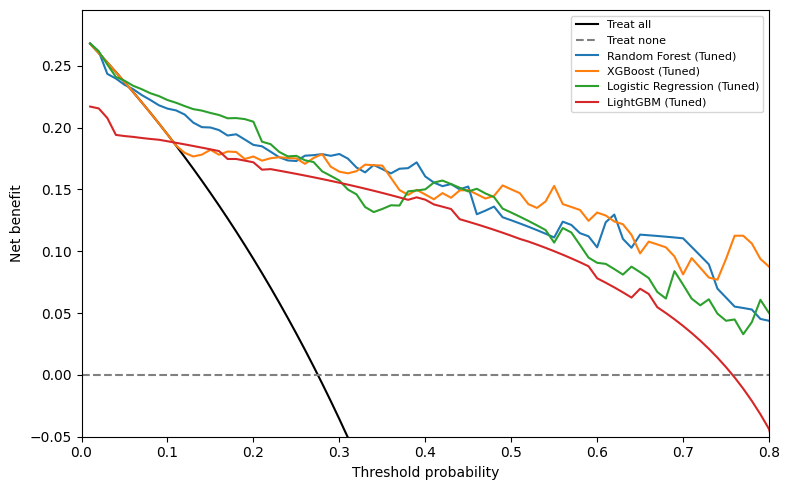

DCA table saved to results/table_dca_net_benefit.csv


In [27]:
thr_grid = np.round(np.arange(0.01, 0.991, 0.01), 2)

def decision_curve(y_true, prob, thresholds=thr_grid):
    y_true = np.asarray(y_true)
    prob = np.asarray(prob)
    n = len(y_true)
    rows = []
    for pt in thresholds:
        pred = prob >= pt
        tp = np.sum(pred & (y_true == 1))
        fp = np.sum(pred & (y_true == 0))
        net_benefit = tp / n - (fp / n) * (pt / (1 - pt))
        rows.append((pt, net_benefit))
    return pd.DataFrame(rows, columns=['threshold', 'net_benefit'])


dca_tables = {}
for name, r in results.items():
    dca_tables[name] = decision_curve(y_test, r['y_prob'])

# Reference strategies
prev_test = y_test.mean()
dca_wide = pd.DataFrame({'threshold': thr_grid})
dca_wide['treat_all'] = prev_test - (1 - prev_test) * (dca_wide['threshold'] / (1 - dca_wide['threshold']))
dca_wide['treat_none'] = 0.0
for name, t in dca_tables.items():
    dca_wide[name] = t['net_benefit'].values
save(dca_wide, 'table_dca_net_benefit')

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(dca_wide.threshold, dca_wide.treat_all, 'k-', label='Treat all')
ax.axhline(0, color='grey', ls='--', label='Treat none')
for name in top4:
    ax.plot(dca_wide.threshold, dca_wide[name], label=name)
ax.set_xlim(0, 0.8)
ax.set_ylim(-0.05, prev_test + 0.02)
ax.set_xlabel('Threshold probability')
ax.set_ylabel('Net benefit')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('figs/fig_dca.png', dpi=180)
plt.show()
print('DCA table saved to results/table_dca_net_benefit.csv')


### 9.5 Subgroup / fairness analysis

Metrics on the held-out test set. Small subgroups are flagged and should not be interpreted as definitive fairness evidence.

In [28]:
bp = results[best_model_name]['y_prob']
bpred = results[best_model_name]['y_pred']

sg_masks = {
    'Male': (X_test['Gender'] == 1).values,
    'Female': (X_test['Gender'] == 0).values,
    'Infant <=12m': (X_test['Age'] <= 12).values,
    'Older >12m': (X_test['Age'] > 12).values,
    'Fully vaccinated': (X_test['Vacc_Full'] == 1).values,
    'Not fully vaccinated': (X_test['Vacc_Full'] == 0).values,
}

rows = []
for g, mask in sg_masks.items():
    yy = y_test[mask]
    n_pos = int(yy.sum())
    ok = 0 < n_pos < len(yy)
    if ok:
        lo, hi = bootstrap_auc_ci(yy, bp[mask])
    else:
        lo, hi = np.nan, np.nan
    rows.append({
        'Group': g, 'N': int(mask.sum()), 'N positive': n_pos,
        'AUC': roc_auc_score(yy, bp[mask]) if ok else np.nan,
        'AUC CI low': lo, 'AUC CI high': hi,
        'Recall': recall_score(yy, bpred[mask], zero_division=0) if n_pos else np.nan,
        'Exploratory (<10 positives)': n_pos < 10,
    })

fairness_results = save(pd.DataFrame(rows), 'table_subgroups')
fairness_results.round(3)


,Group,N,N positive,AUC,AUC CI low,AUC CI high,Recall,Exploratory (<10 positives)
0,Male,102,32,0.930,0.859,0.982,0.688,False
1,Female,58,12,0.853,0.679,0.967,0.667,False
2,Infant <=12m,57,21,0.877,0.770,0.963,0.619,False
3,Older >12m,103,23,0.902,0.802,0.982,0.739,False
4,Fully vaccinated,139,36,0.891,0.814,0.954,0.667,False
5,Not fully vaccinated,21,8,0.981,0.913,1.000,0.750,True


### 9.6 Ten-seed sensitivity analysis

The primary split stays fixed at seed 42. This repeats the evaluation across ten seeds, using the already-tuned pipelines (hyperparameters NOT re-tuned).

In [29]:
SENSITIVITY_SEEDS = [0, 7, 13, 21, 42, 99, 123, 200, 303, 512]
if QUICK:
    SENSITIVITY_SEEDS = SENSITIVITY_SEEDS[:3]

SENS_MODELS = [best_model_name]
if 'XGBoost (Tuned)' not in SENS_MODELS:
    SENS_MODELS.append('XGBoost (Tuned)')

sensitivity_rows = []
for seed in SENSITIVITY_SEEDS:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    for name in SENS_MODELS:
        m = clone(models[name])
        params = {'smote__random_state': seed}
        if 'random_state' in m.named_steps['clf'].get_params():
            params['clf__random_state'] = seed
        m.set_params(**params)
        m.fit(Xtr, ytr)
        sensitivity_rows.append({
            'Seed': seed, 'Model': name,
            'AUC': roc_auc_score(yte, m.predict_proba(Xte)[:, 1]),
        })

sensitivity_results = save(pd.DataFrame(sensitivity_rows), 'table_sensitivity_seeds')

sens_summary = sensitivity_results.groupby('Model')['AUC'].agg(
    mean='mean', sd=lambda s: s.std(ddof=1), min='min', max='max')
save(sens_summary.reset_index(), 'table_sensitivity_summary')
sens_summary.round(4)


,mean,sd,min,max
Model,,,,
Random Forest (Tuned),0.8927,0.0217,0.8672,0.9289
XGBoost (Tuned),0.8846,0.0262,0.8458,0.9244


### 9.7 CERS (Community Exposure Risk Score)

Four community variables, min-max scaled with TRAINING limits. Weights come from a logistic regression fitted on the training set (negative coefficients truncated to 0 and flagged), compared against expert weights.

In [30]:
def cers_inputs(D):
    return pd.DataFrame({
        'PPR': D['PersonsPerRoom'],
        'Smk': D['SmokersAtHome'],
        'VR': 0.5 * D['Vacc_Partial'] + 1.0 * D['Vacc_None'],   # 0 full, 0.5 partial, 1 none
        'HHS': D['HouseholdSize'],
    })

c_tr = cers_inputs(X_train)
c_te = cers_inputs(X_test)

c_imp = SimpleImputer(strategy='median').fit(c_tr)
c_mm = MinMaxScaler().fit(c_imp.transform(c_tr))          # limits from TRAINING data
Z_tr = c_mm.transform(c_imp.transform(c_tr))
Z_te = np.clip(c_mm.transform(c_imp.transform(c_te)), 0, 1)

cers_lr = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=SEED).fit(Z_tr, y_train)
coef = cers_lr.coef_[0]

w_opt = np.clip(coef, 0, None)                            # truncate negatives at 0
if w_opt.sum() > 0:
    w_opt = w_opt / w_opt.sum()
w_exp = np.array([0.35, 0.30, 0.20, 0.15])

cers_weights = pd.DataFrame({
    'Variable': c_tr.columns,
    'LR coefficient (raw)': coef,
    'Optimised weight': w_opt,
    'Expert weight': w_exp,
})
cers_weights['Truncated (negative coef)'] = coef < 0
save(cers_weights, 'table_cers_weights')

cers_auc = pd.DataFrame([
    {'Score': 'Expert CERS',
     'AUC_train': roc_auc_score(y_train, Z_tr @ w_exp),
     'AUC_test': roc_auc_score(y_test, Z_te @ w_exp)},
    {'Score': 'Optimised CERS',
     'AUC_train': roc_auc_score(y_train, Z_tr @ w_opt),
     'AUC_test': roc_auc_score(y_test, Z_te @ w_opt)},
])
save(cers_auc, 'table_cers_auc')

print(cers_weights.round(4).to_string())
print(cers_auc.round(4).to_string())


  Variable  LR coefficient (raw)  Optimised weight  Expert weight  Truncated (negative coef)
0      PPR               -0.6412            0.0000           0.35                       True
1      Smk                0.2969            0.1755           0.30                      False
2       VR                1.1812            0.6983           0.20                      False
3      HHS                0.2134            0.1262           0.15                      False
            Score  AUC_train  AUC_test
0     Expert CERS     0.5422    0.5316
1  Optimised CERS     0.5660    0.5400


### 9.8 CPSS (Community Pneumonia Score)

Derived from a training-set logistic regression on five easily-collected predictors. Points = coefficient / largest |coefficient| x 5, rounded to the nearest 0.5. **Check signs:** wheezing is protective in this dataset, so any score that adds it will invert.

In [31]:
def cpss_inputs(D, crowd_cut=3.0):   # crowd_cut is an ASSUMPTION - justify in the paper
    return pd.DataFrame({
        'Wheezing': D['Wheezing'],
        'Fever': D['Fever'],
        'Crowding': (D['PersonsPerRoom'] >= crowd_cut).astype(float),
        'VaccRisk': 0.5 * D['Vacc_Partial'] + 1.0 * D['Vacc_None'],
        'Smoking': D['SmokersAtHome'],
    })

s_tr = cpss_inputs(X_train)
s_te = cpss_inputs(X_test)

s_imp = SimpleImputer(strategy='median').fit(s_tr)
S_tr = s_imp.transform(s_tr)
S_te = s_imp.transform(s_te)

cp_lr = LogisticRegression(C=1e6, max_iter=2000).fit(S_tr, y_train)   # ~unpenalised
beta = cp_lr.coef_[0]

MAX_POINTS = 5.0
points = np.round(beta / np.max(np.abs(beta)) * MAX_POINTS * 2) / 2   # nearest half point

sc_tr = S_tr @ points
sc_te = S_te @ points

cpss_table = pd.DataFrame({
    'Predictor': s_tr.columns,
    'log-odds': beta,
    'odds ratio': np.exp(beta),
    'Points': points,
})
save(cpss_table, 'table_cpss_points')
print(cpss_table.round(3).to_string())
print('NEGATIVE log-odds / points = protective in THIS dataset (expected for Wheezing).')

# Legacy published weights, for comparison only
legacy_weights = np.array([2.0, 1.5, 1.0, 1.0, 0.5])
lo, hi = bootstrap_auc_ci(y_test, sc_te)
cpss_auc = pd.DataFrame([
    {'Score': 'CPSS derived (train)',
     'AUC_train': roc_auc_score(y_train, sc_tr), 'AUC_test': roc_auc_score(y_test, sc_te),
     'AUC_test_CI_low': lo, 'AUC_test_CI_high': hi},
    {'Score': 'Legacy fixed weights (2,1.5,1,1,0.5)',
     'AUC_train': roc_auc_score(y_train, S_tr @ legacy_weights),
     'AUC_test': roc_auc_score(y_test, S_te @ legacy_weights),
     'AUC_test_CI_low': np.nan, 'AUC_test_CI_high': np.nan},
])
save(cpss_auc, 'table_cpss_auc')
print(cpss_auc.round(4).to_string())

# Observed pneumonia rate by score (use to justify any risk bands)
sp = pd.DataFrame({
    'set': ['train'] * len(sc_tr) + ['test'] * len(sc_te),
    'score': np.r_[sc_tr, sc_te],
    'y': np.r_[y_train, y_test],
})
cpss_prev = sp.groupby(['set', 'score'])['y'].agg(n='size', n_pos='sum', prevalence='mean').reset_index()
save(cpss_prev, 'table_cpss_score_prevalence')
cpss_prev


  Predictor  log-odds  odds ratio  Points
0  Wheezing    -2.352       0.095    -5.0
1     Fever     1.139       3.124     2.5
2  Crowding    -0.041       0.960    -0.0
3  VaccRisk     1.795       6.018     4.0
4   Smoking     0.400       1.492     1.0
NEGATIVE log-odds / points = protective in THIS dataset (expected for Wheezing).
                                  Score  AUC_train  AUC_test  AUC_test_CI_low  AUC_test_CI_high
0                  CPSS derived (train)     0.8271    0.8475           0.7707            0.9153
1  Legacy fixed weights (2,1.5,1,1,0.5)     0.3415    0.2745              NaN               NaN


,set,score,n,n_pos,prevalence
0,test,-5.0,28,2,0.071429
1,test,-4.0,17,2,0.117647
2,test,-3.0,3,0,0.000000
3,test,-2.5,34,2,0.058824
4,test,-2.0,1,0,0.000000
5,test,-1.5,17,1,0.058824
6,test,-0.5,6,3,0.500000
7,test,0.0,4,2,0.500000
8,test,0.5,5,0,0.000000
9,test,1.0,2,1,0.500000


### 9.9 Hospital model vs community-level (CHW-available) model

In [32]:
# CHW list excludes lab tests, chest X-ray, auscultation (crackles) and pulse oximetry.
CHW_FEATURES = ['Age', 'Gender', 'Siblings', 'Prematurity', 'Breastfed', 'PriorRespAdm',
                'Temperature', 'RespiratoryRate', 'Fever', 'Wheezing', 'NasalFlaring', 'Cyanosis',
                'HouseholdSize', 'Rooms', 'PersonsPerRoom', 'SmokersAtHome', 'VitaminA',
                'Vacc_Full', 'Vacc_Partial', 'Vacc_None', 'HibDoses', 'PneumoDoses']
assert all(c in FEATURE_COLS for c in CHW_FEATURES)

CHW_MODELS = [best_model_name]
if 'Logistic Regression (Tuned)' not in CHW_MODELS:
    CHW_MODELS.append('Logistic Regression (Tuned)')

rows = []
for name in CHW_MODELS:
    full_cv = cv_summary(cross_val_score(clone(models[name]), X_train, y_train,
                                         cv=cv_outer, scoring='roc_auc', n_jobs=-1))
    chw_cv = cv_summary(cross_val_score(clone(models[name]), X_train[CHW_FEATURES], y_train,
                                        cv=cv_outer, scoring='roc_auc', n_jobs=-1))
    m = clone(models[name]).fit(X_train[CHW_FEATURES], y_train)
    p = m.predict_proba(X_test[CHW_FEATURES])[:, 1]
    lo, hi = bootstrap_auc_ci(y_test, p)
    rows.append({
        'Model': name,
        'Full_CV_AUC': full_cv['mean'],
        'CHW_CV_AUC': chw_cv['mean'],
        'CHW_test_AUC': roc_auc_score(y_test, p),
        'CHW_test_CI_low': lo, 'CHW_test_CI_high': hi,
    })

chw_results = save(pd.DataFrame(rows), 'table_hospital_vs_chw')
chw_results.round(4)


,Model,Full_CV_AUC,CHW_CV_AUC,CHW_test_AUC,CHW_test_CI_low,CHW_test_CI_high
0,Random Forest (Tuned),0.8942,0.8557,0.8595,0.7921,0.9201
1,Logistic Regression (Tuned),0.8836,0.8481,0.8317,0.7588,0.9018


## 10. Figures

Publication-ready figures: ROC curves, CV-AUC with CIs, feature importance, confusion matrices, SHAP summary, vaccination prevalence, and crowding analysis.

In [33]:
BLUE, GOLD, RED, GREEN = '#1a3a5c', '#e8a020', '#c0392b', '#27ae60'
COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
          '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf', '#aec7e8']


**Fig 1: ROC Curves**

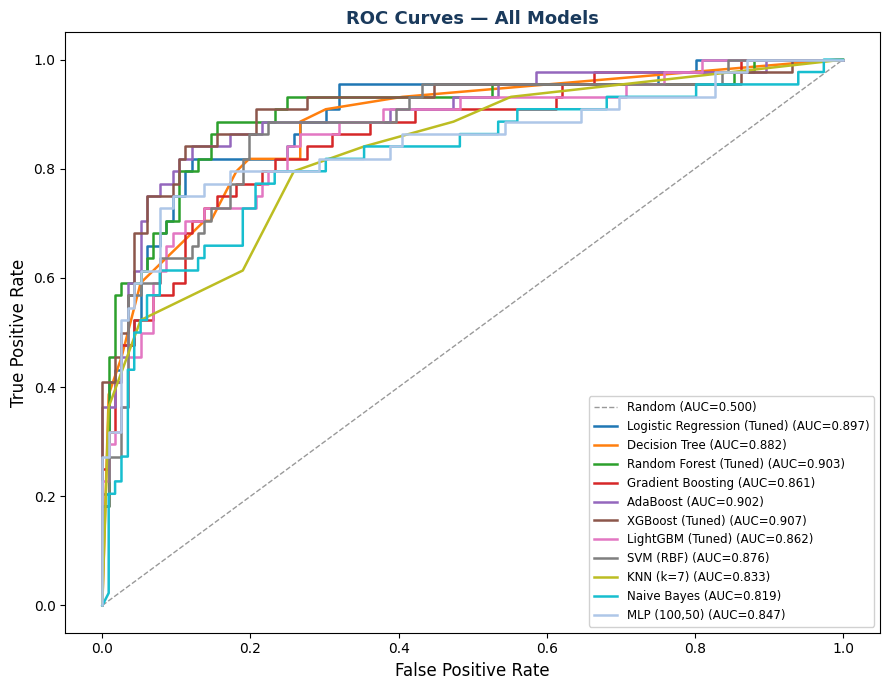

In [34]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, lw=1, label='Random (AUC=0.500)')
for (name, res), col in zip(results.items(), COLORS):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax.plot(fpr, tpr, color=col, lw=1.8,
            label=f"{name} (AUC={res['AUC-ROC']:.3f})")
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models', fontsize=13, fontweight='bold', color=BLUE)
ax.legend(loc='lower right', fontsize=8.5, framealpha=0.9)
plt.tight_layout()
plt.savefig('figs/fig1_roc_curves.png', dpi=180, bbox_inches='tight')
plt.show()


**Fig 2: CV-AUC with 95% confidence intervals**

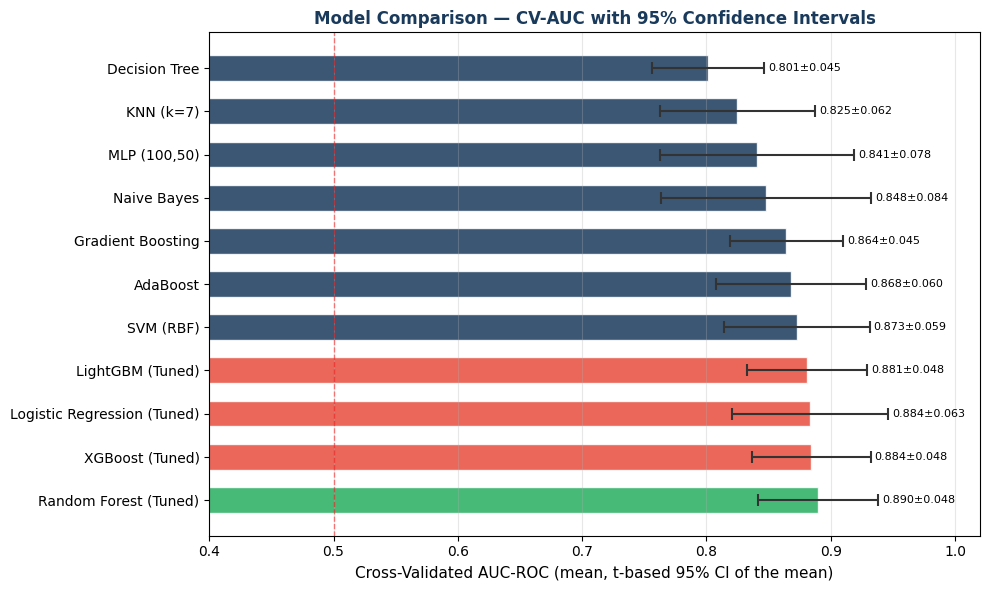

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))

names_sorted = sorted(results.keys(), key=lambda n: results[n]['CV-AUC Mean'], reverse=True)
means = [results[n]['CV-AUC Mean'] for n in names_sorted]
ci95  = [results[n]['CV-AUC CI half'] for n in names_sorted]

bar_colors = []
for m, n in zip(means, names_sorted):
    if m == max(means):
        bar_colors.append(GREEN)
    elif '(Tuned)' in n:
        bar_colors.append('#e74c3c')
    else:
        bar_colors.append(BLUE)

ax.barh(range(len(names_sorted)), means, xerr=ci95, color=bar_colors, alpha=0.85,
        edgecolor='white', height=0.6,
        error_kw={'elinewidth': 1.5, 'capsize': 4, 'capthick': 1.5, 'ecolor': '#333'})
ax.set_yticks(range(len(names_sorted)))
ax.set_yticklabels(names_sorted, fontsize=10)
ax.set_xlabel('Cross-Validated AUC-ROC (mean, t-based 95% CI of the mean)', fontsize=11)
ax.set_title('Model Comparison — CV-AUC with 95% Confidence Intervals',
             fontsize=12, fontweight='bold', color=BLUE)
ax.axvline(0.5, color='red', lw=1, linestyle='--', alpha=0.5)
for i, (m, c) in enumerate(zip(means, ci95)):
    ax.text(m + c + 0.003, i, f'{m:.3f}±{c:.3f}', va='center', fontsize=8)
ax.set_xlim(0.4, 1.02)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('figs/fig2_cv_auc_ci.png', dpi=180, bbox_inches='tight')
plt.show()


**Fig 3: Feature Importance (top 15, color-coded by category)**

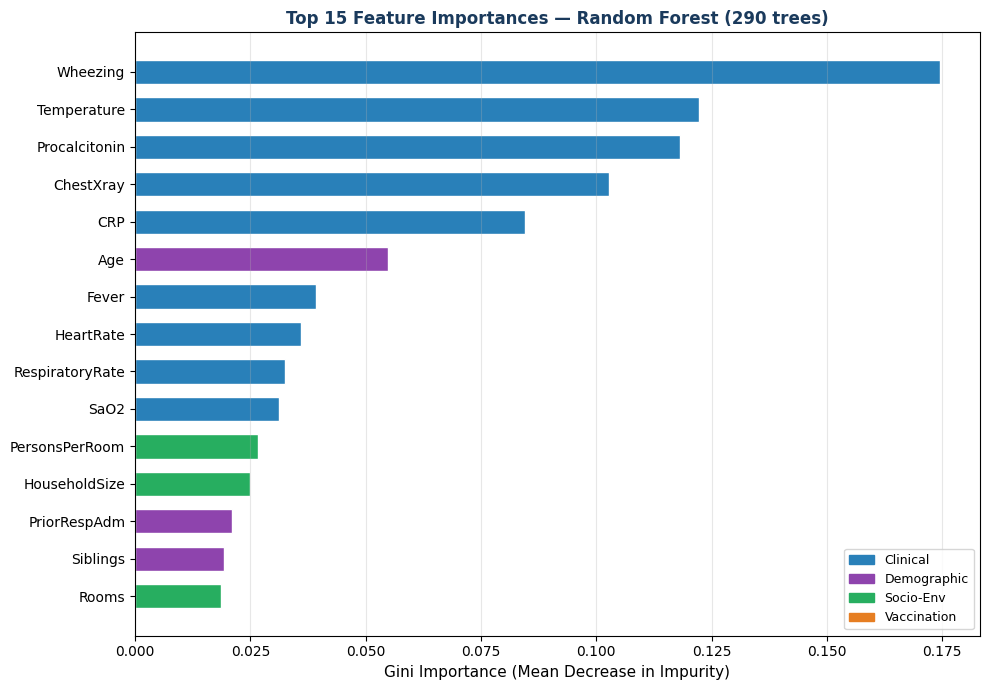

In [36]:
cats = {
    'CRP': 'Clinical', 'Procalcitonin': 'Clinical', 'SaO2': 'Clinical',
    'Temperature': 'Clinical', 'RespiratoryRate': 'Clinical', 'HeartRate': 'Clinical',
    'Fever': 'Clinical', 'Crackles': 'Clinical', 'Wheezing': 'Clinical',
    'NasalFlaring': 'Clinical', 'Cyanosis': 'Clinical', 'ChestXray': 'Clinical',
    'Age': 'Demographic', 'Gender': 'Demographic', 'Siblings': 'Demographic',
    'Prematurity': 'Demographic', 'Breastfed': 'Demographic', 'PriorRespAdm': 'Demographic',
    'HouseholdSize': 'Socio-Env', 'Rooms': 'Socio-Env', 'PersonsPerRoom': 'Socio-Env',
    'SmokersAtHome': 'Socio-Env', 'VitaminA': 'Socio-Env',
    'Vacc_Full': 'Vaccination', 'Vacc_Partial': 'Vaccination', 'Vacc_None': 'Vaccination',
    'HibDoses': 'Vaccination', 'PneumoDoses': 'Vaccination',
}
cat_colors = {'Clinical': '#2980b9', 'Demographic': '#8e44ad',
              'Socio-Env': '#27ae60', 'Vaccination': '#e67e22'}

top_n = 15
fi_top = feat_imp.head(top_n)
bar_colors = [cat_colors.get(cats.get(f, 'Clinical'), '#555') for f in fi_top['Feature']]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(fi_top)), fi_top['Importance'].values, color=bar_colors,
        edgecolor='white', height=0.65)
ax.set_yticks(range(len(fi_top)))
ax.set_yticklabels(fi_top['Feature'].values, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel('Gini Importance (Mean Decrease in Impurity)', fontsize=11)
ax.set_title(f'Top {top_n} Feature Importances — Random Forest '
             f'({rf_clf.get_params()["n_estimators"]} trees)',
             fontsize=12, fontweight='bold', color=BLUE)
patches = [mpatches.Patch(color=c, label=l) for l, c in cat_colors.items()]
ax.legend(handles=patches, loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('figs/fig3_feature_importance.png', dpi=180, bbox_inches='tight')
plt.show()


**Fig 4: Confusion matrices (top 3 models)**

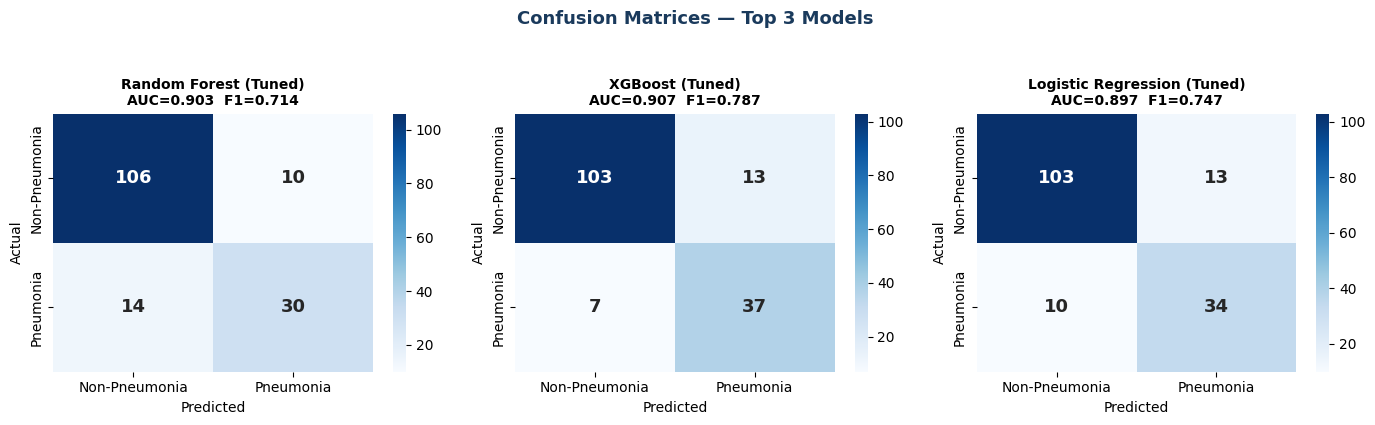

In [37]:
top3 = sorted(results.keys(), key=lambda n: results[n]['CV-AUC Mean'], reverse=True)[:3]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, top3):
    cm = confusion_matrix(y_test, results[name]['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-Pneumonia', 'Pneumonia'],
                yticklabels=['Non-Pneumonia', 'Pneumonia'],
                annot_kws={'size': 13, 'weight': 'bold'})
    ax.set_title(f"{name}\nAUC={results[name]['AUC-ROC']:.3f}  F1={results[name]['F1']:.3f}",
                 fontsize=10, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual', fontsize=10)
fig.suptitle('Confusion Matrices — Top 3 Models', fontsize=13, fontweight='bold',
             color=BLUE, y=1.05)
plt.tight_layout()
plt.savefig('figs/fig4_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()


**Fig 5: SHAP Summary Plot**

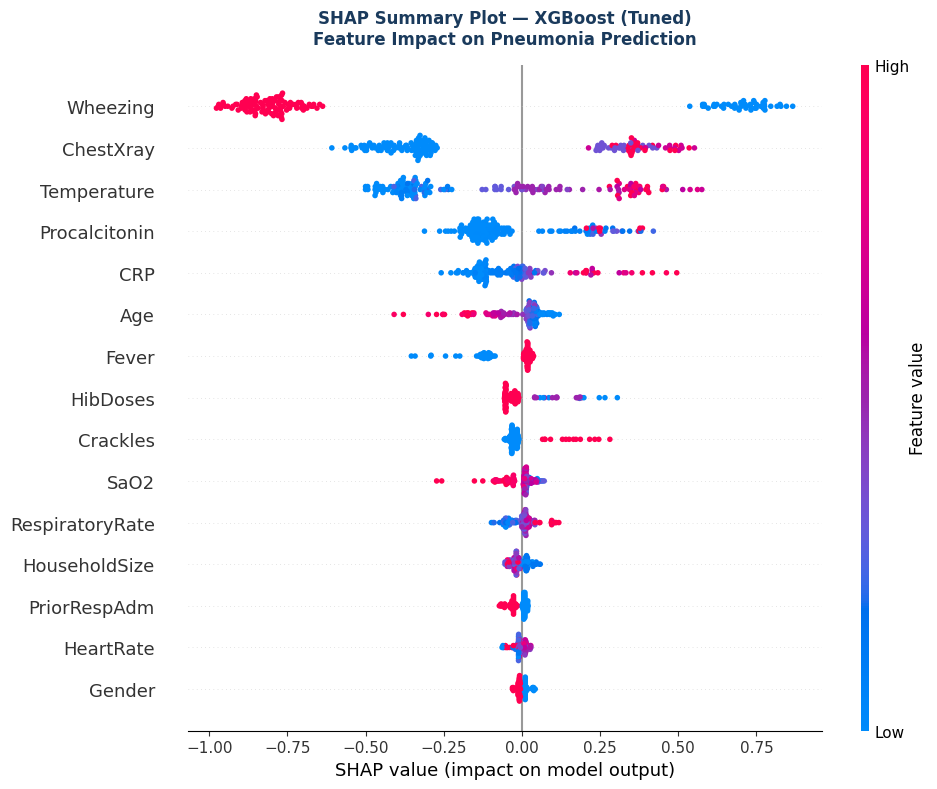

In [38]:
shap.summary_plot(shap_vals, Xtest_transformed, feature_names=FEATURE_COLS,
                  max_display=15, show=False, plot_size=(10, 8))
plt.title('SHAP Summary Plot — XGBoost (Tuned)\nFeature Impact on Pneumonia Prediction',
          fontsize=12, fontweight='bold', color=BLUE, pad=15)
plt.tight_layout()
plt.savefig('figs/fig5_shap_summary.png', dpi=180, bbox_inches='tight')
plt.show()


**Fig 6: Pneumonia prevalence by vaccination status**

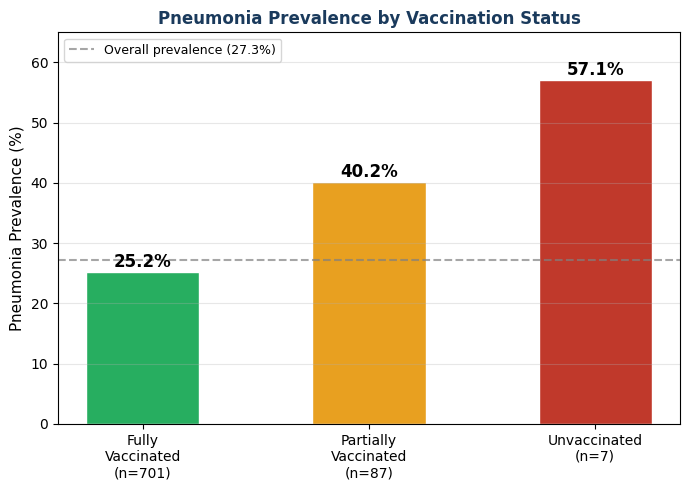

In [39]:
fig, ax = plt.subplots(figsize=(7, 5))
labels = [f"Fully\nVaccinated\n(n={vax_prev['Full'][1]})",
          f"Partially\nVaccinated\n(n={vax_prev['Partial'][1]})",
          f"Unvaccinated\n(n={vax_prev['None'][1]})"]
prevs = [vax_prev['Full'][0] * 100, vax_prev['Partial'][0] * 100, vax_prev['None'][0] * 100]

bars = ax.bar(labels, prevs, color=[GREEN, GOLD, RED], edgecolor='white', width=0.5)
for bar, val in zip(bars, prevs):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
            f'{val:.1f}%', ha='center', fontsize=12, fontweight='bold')
ax.set_ylabel('Pneumonia Prevalence (%)', fontsize=11)
ax.set_title('Pneumonia Prevalence by Vaccination Status', fontsize=12,
             fontweight='bold', color=BLUE)
ax.set_ylim(0, 65)
ax.axhline(feat['target'].mean() * 100, color='grey', lw=1.5, linestyle='--', alpha=0.7,
           label=f"Overall prevalence ({feat['target'].mean() * 100:.1f}%)")
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('figs/fig6_vaccination_prevalence.png', dpi=180, bbox_inches='tight')
plt.show()


**Fig 7: Household crowding analysis**

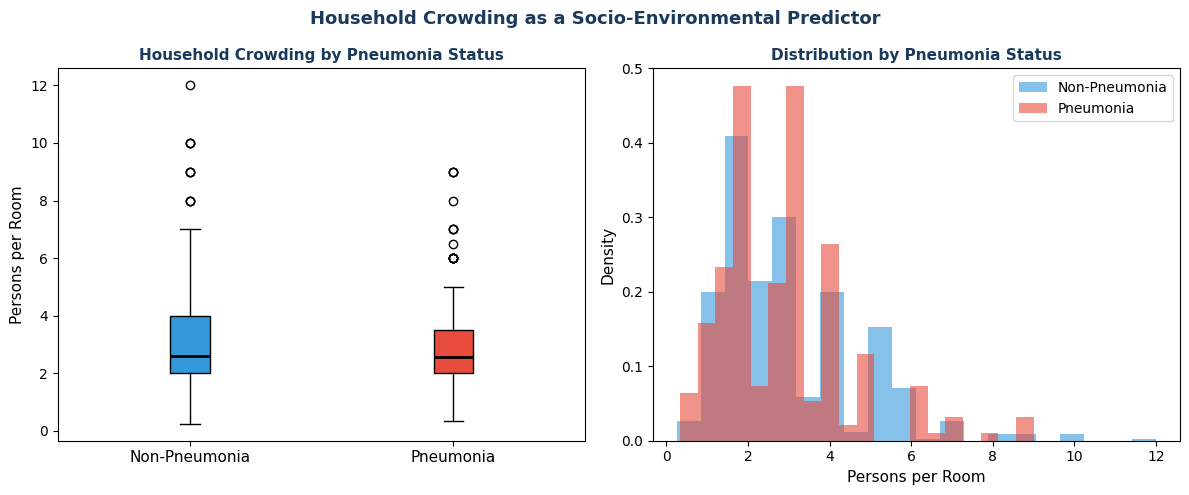

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

data0 = feat.loc[feat['target'] == 0, 'PersonsPerRoom'].dropna()
data1 = feat.loc[feat['target'] == 1, 'PersonsPerRoom'].dropna()

ax = axes[0]
bp = ax.boxplot([data0, data1], patch_artist=True, medianprops={'color': 'black', 'linewidth': 2})
bp['boxes'][0].set_facecolor('#3498db')
bp['boxes'][1].set_facecolor('#e74c3c')
ax.set_xticklabels(['Non-Pneumonia', 'Pneumonia'], fontsize=11)
ax.set_ylabel('Persons per Room', fontsize=11)
ax.set_title('Household Crowding by Pneumonia Status', fontsize=11, fontweight='bold', color=BLUE)

ax2 = axes[1]
ax2.hist(data0, bins=20, alpha=0.6, color='#3498db', label='Non-Pneumonia', density=True)
ax2.hist(data1, bins=20, alpha=0.6, color='#e74c3c', label='Pneumonia', density=True)
ax2.set_xlabel('Persons per Room', fontsize=11)
ax2.set_ylabel('Density', fontsize=11)
ax2.set_title('Distribution by Pneumonia Status', fontsize=11, fontweight='bold', color=BLUE)
ax2.legend(fontsize=10)

fig.suptitle('Household Crowding as a Socio-Environmental Predictor',
             fontsize=13, fontweight='bold', color=BLUE)
plt.tight_layout()
plt.savefig('figs/fig7_crowding_analysis.png', dpi=180, bbox_inches='tight')
plt.show()


## 10b. Additional Figures for the Manuscript

Calibration, DeLong/McNemar heat maps, SHAP dependence and individual explanations, CERS and CPSS figures, subgroups, sensitivity, ablation. All computed from this run and saved to `figs/` at 300 dpi.

In [41]:
short = lambda s: s.replace(' (Tuned)', '')
DPI = 300


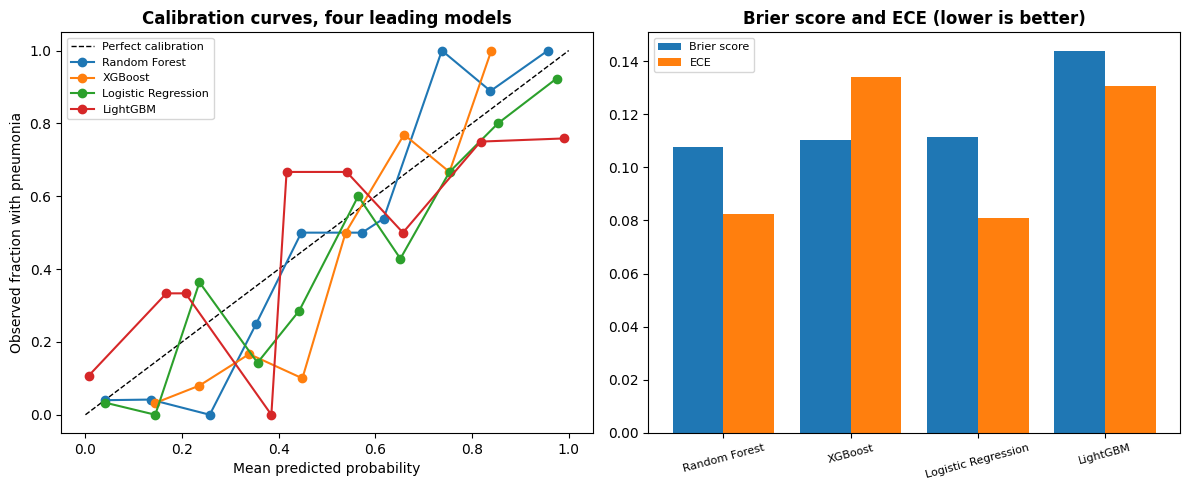

In [42]:
# ---- Fig A: calibration curves + Brier / ECE ----
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect calibration')
for name in top4:
    frac, mean_p = calibration_curve(y_test, results[name]['y_prob'], n_bins=10, strategy='uniform')
    ax.plot(mean_p, frac, marker='o', lw=1.5, label=short(name))
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed fraction with pneumonia')
ax.set_title('Calibration curves, four leading models', fontweight='bold')
ax.legend(fontsize=8)

cal4 = calibration_results.set_index('Model').loc[top4]
x = np.arange(len(top4))
ax = axes[1]
ax.bar(x - 0.2, cal4['Brier'], 0.4, label='Brier score')
ax.bar(x + 0.2, cal4['ECE'], 0.4, label='ECE')
ax.set_xticks(x)
ax.set_xticklabels([short(n) for n in top4], fontsize=8, rotation=15)
ax.set_title('Brier score and ECE (lower is better)', fontweight='bold')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('figs/figA_calibration.png', dpi=DPI, bbox_inches='tight')
plt.show()


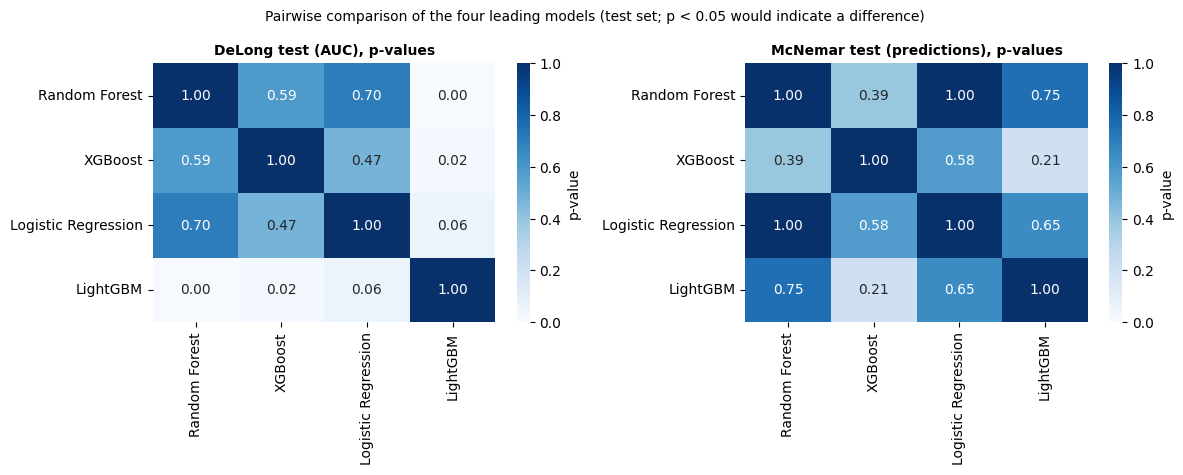

In [43]:
# ---- Fig B: DeLong and McNemar p-value heat maps ----
def pmat(col):
    M = pd.DataFrame(1.0, index=top4, columns=top4)
    for _, r in pairwise_tests.iterrows():
        M.loc[r['model_1'], r['model_2']] = r[col]
        M.loc[r['model_2'], r['model_1']] = r[col]
    M.index = [short(n) for n in top4]
    M.columns = [short(n) for n in top4]
    return M

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, col, ttl in zip(axes, ['delong_p', 'mcnemar_p'],
        ['DeLong test (AUC), p-values', 'McNemar test (predictions), p-values']):
    sns.heatmap(pmat(col), annot=True, fmt='.2f', vmin=0, vmax=1, cmap='Blues',
                cbar_kws={'label': 'p-value'}, ax=ax)
    ax.set_title(ttl, fontweight='bold', fontsize=10)
plt.suptitle('Pairwise comparison of the four leading models (test set; '
             'p < 0.05 would indicate a difference)', fontsize=10)
plt.tight_layout()
plt.savefig('figs/figB_delong_mcnemar.png', dpi=DPI, bbox_inches='tight')
plt.show()


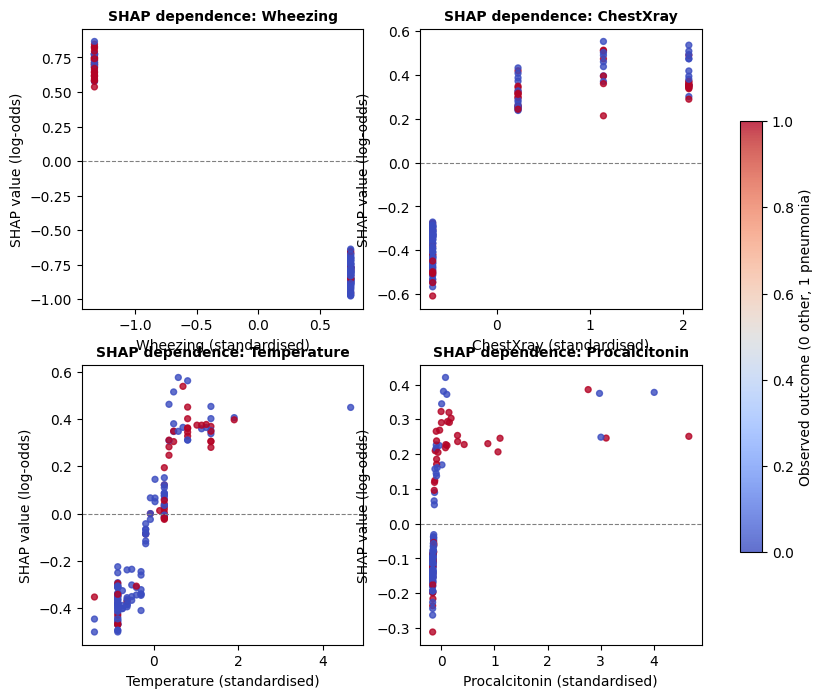

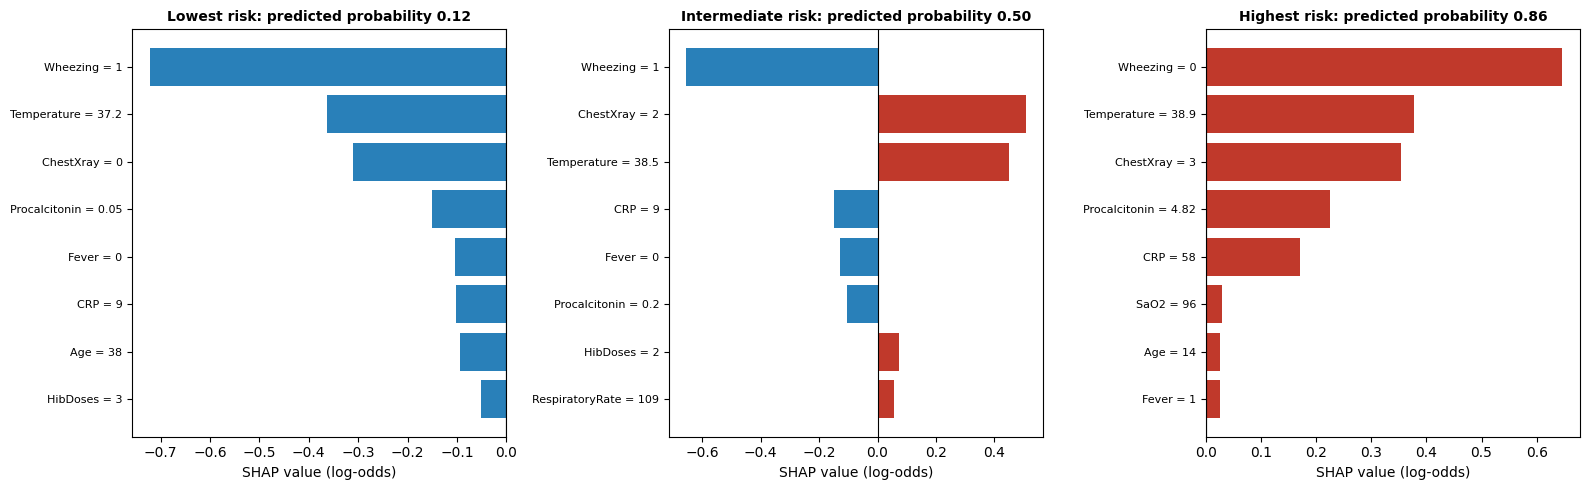

In [44]:
# ---- Fig C: SHAP dependence for the four most influential predictors ----
top_feats = shap_dir['feature'].head(4).tolist()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, f in zip(axes.ravel(), top_feats):
    j = FEATURE_COLS.index(f)
    sc = ax.scatter(Xtest_transformed[:, j], shap_vals[:, j], c=y_test,
                    cmap='coolwarm', s=18, alpha=0.8)
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.set_xlabel(f + ' (standardised)')
    ax.set_ylabel('SHAP value (log-odds)')
    ax.set_title('SHAP dependence: ' + f, fontweight='bold', fontsize=10)
fig.colorbar(sc, ax=axes, label='Observed outcome (0 other, 1 pneumonia)', shrink=0.7)
plt.savefig('figs/figC_shap_dependence.png', dpi=DPI, bbox_inches='tight')
plt.show()

# ---- Fig D: individual explanations ----
p_x = xgb_pipe.predict_proba(X_test)[:, 1]
picks = [('Lowest risk', int(np.argmin(p_x))),
         ('Intermediate risk', int(np.argmin(np.abs(p_x - 0.5)))),
         ('Highest risk', int(np.argmax(p_x)))]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (ttl, i) in zip(axes, picks):
    order = np.argsort(-np.abs(shap_vals[i]))[:8][::-1]
    vals = shap_vals[i, order]
    labels = [f'{FEATURE_COLS[j]} = {X_test.iloc[i, j]:.3g}' for j in order]
    colors = ['#c0392b' if v > 0 else '#2980b9' for v in vals]
    ax.barh(range(len(order)), vals, color=colors)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_title(f'{ttl}: predicted probability {p_x[i]:.2f}', fontweight='bold', fontsize=10)
    ax.set_xlabel('SHAP value (log-odds)')
plt.tight_layout()
plt.savefig('figs/figD_shap_individual.png', dpi=DPI, bbox_inches='tight')
plt.show()


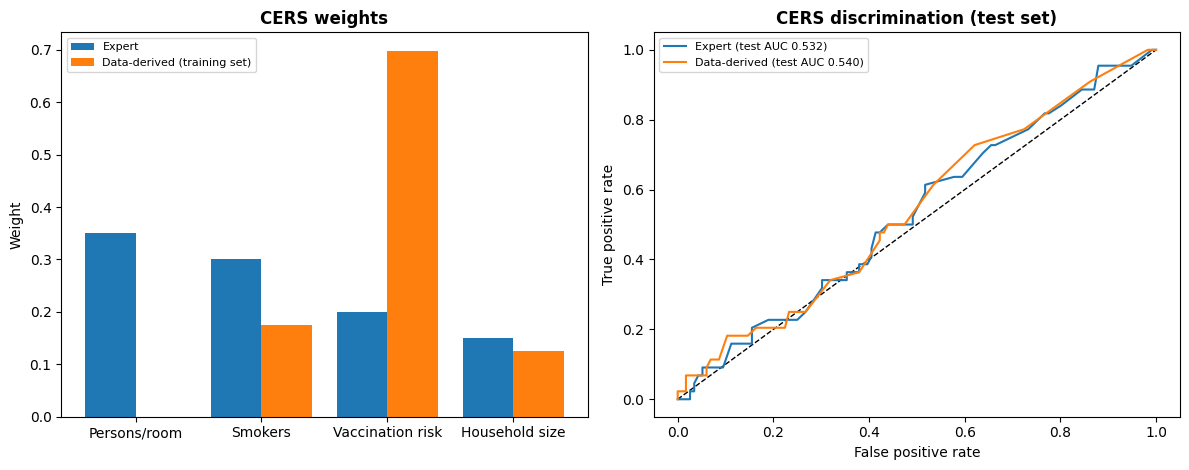

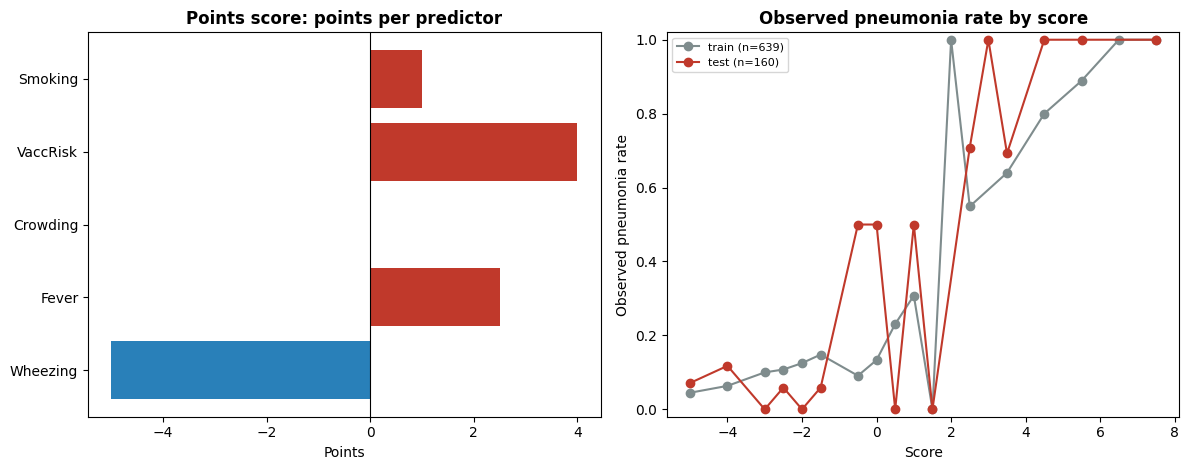

In [45]:
# ---- Fig E: community exposure score ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
x = np.arange(len(cers_weights))
ax.bar(x - 0.2, cers_weights['Expert weight'], 0.4, label='Expert')
ax.bar(x + 0.2, cers_weights['Optimised weight'], 0.4, label='Data-derived (training set)')
ax.set_xticks(x)
ax.set_xticklabels(['Persons/room', 'Smokers', 'Vaccination risk', 'Household size'])
ax.set_ylabel('Weight')
ax.legend(fontsize=8)
ax.set_title('CERS weights', fontweight='bold')

ax = axes[1]
ax.plot([0, 1], [0, 1], 'k--', lw=1)
for lab, w in [('Expert', w_exp), ('Data-derived', w_opt)]:
    fpr, tpr, _ = roc_curve(y_test, Z_te @ w)
    auc = roc_auc_score(y_test, Z_te @ w)
    ax.plot(fpr, tpr, label=f'{lab} (test AUC {auc:.3f})')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.legend(fontsize=8)
ax.set_title('CERS discrimination (test set)', fontweight='bold')

plt.tight_layout()
plt.savefig('figs/figE_cers.png', dpi=DPI, bbox_inches='tight')
plt.show()

# ---- Fig F: points score ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
colors = ['#c0392b' if v > 0 else '#2980b9' for v in cpss_table['Points']]
ax.barh(cpss_table['Predictor'], cpss_table['Points'], color=colors)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Points')
ax.set_title('Points score: points per predictor', fontweight='bold')

ax = axes[1]
for set_name, col in [('train', '#7f8c8d'), ('test', '#c0392b')]:
    d = cpss_prev[cpss_prev['set'] == set_name]
    ax.plot(d['score'], d['prevalence'], marker='o', color=col,
            label=f"{set_name} (n={int(d['n'].sum())})")
ax.set_xlabel('Score')
ax.set_ylabel('Observed pneumonia rate')
ax.set_ylim(-0.02, 1.02)
ax.legend(fontsize=8)
ax.set_title('Observed pneumonia rate by score', fontweight='bold')

plt.tight_layout()
plt.savefig('figs/figF_points_score.png', dpi=DPI, bbox_inches='tight')
plt.show()


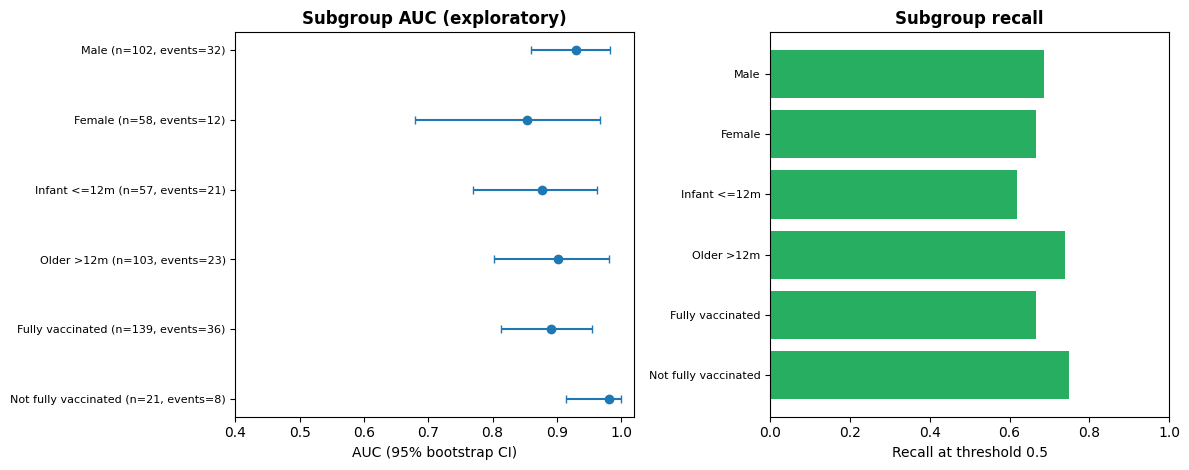

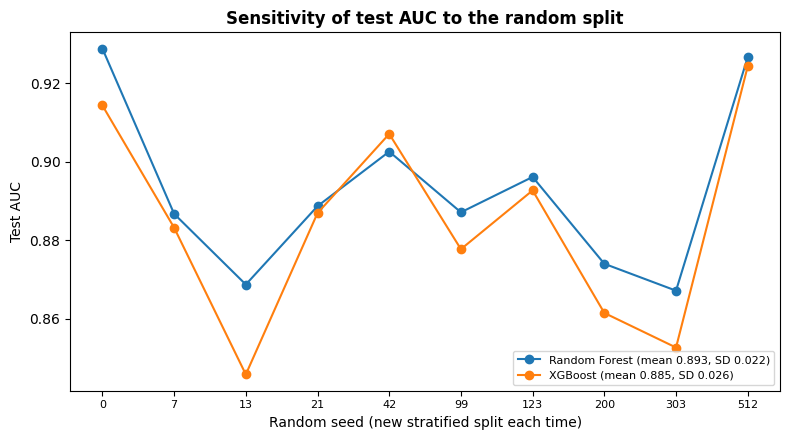

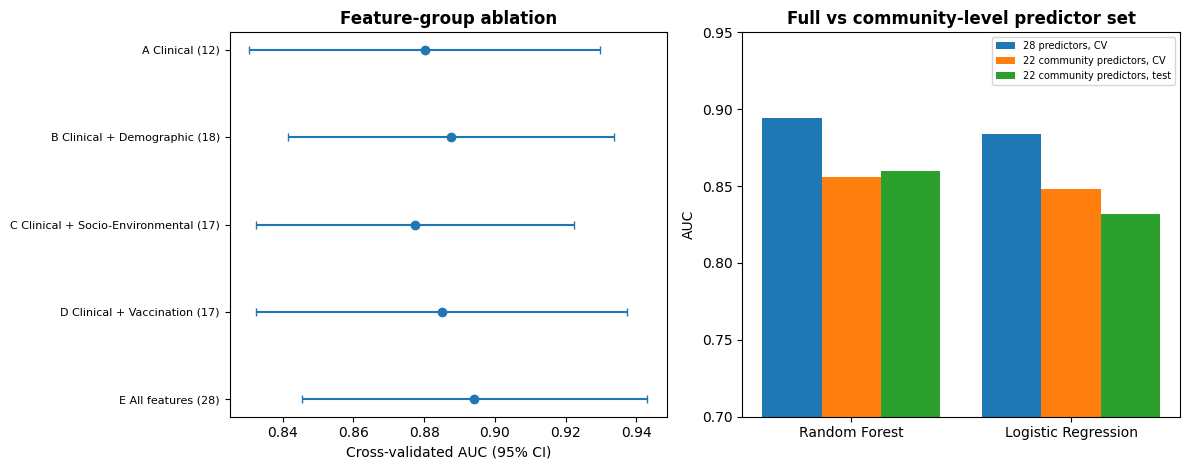

Saved figA..figI to figs/


In [46]:
# ---- Fig G: subgroup AUC and recall ----
fr = fairness_results.copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
yy = np.arange(len(fr))[::-1]
ok = fr['AUC'].notna()
xerr_lo = fr.loc[ok, 'AUC'] - fr.loc[ok, 'AUC CI low']
xerr_hi = fr.loc[ok, 'AUC CI high'] - fr.loc[ok, 'AUC']
ax.errorbar(fr.loc[ok, 'AUC'], yy[ok.values], xerr=[xerr_lo, xerr_hi], fmt='o', capsize=3)
ax.set_yticks(yy)
ax.set_yticklabels([f"{g} (n={n}, events={e})" for g, n, e in
                    zip(fr['Group'], fr['N'], fr['N positive'])], fontsize=8)
ax.set_xlabel('AUC (95% bootstrap CI)')
ax.set_xlim(0.4, 1.02)
ax.set_title('Subgroup AUC (exploratory)', fontweight='bold')

ax = axes[1]
ax.barh(yy, fr['Recall'], color='#27ae60')
ax.set_yticks(yy)
ax.set_yticklabels(fr['Group'], fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel('Recall at threshold 0.5')
ax.set_title('Subgroup recall', fontweight='bold')

plt.tight_layout()
plt.savefig('figs/figG_subgroups.png', dpi=DPI, bbox_inches='tight')
plt.show()

# ---- Fig H: ten-seed sensitivity ----
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, d in sensitivity_results.groupby('Model'):
    ax.plot(range(len(d)), d['AUC'].values, marker='o',
            label=f"{short(name)} (mean {d['AUC'].mean():.3f}, SD {d['AUC'].std(ddof=1):.3f})")
ax.set_xticks(range(len(SENSITIVITY_SEEDS)))
ax.set_xticklabels(SENSITIVITY_SEEDS, fontsize=8)
ax.set_xlabel('Random seed (new stratified split each time)')
ax.set_ylabel('Test AUC')
ax.legend(fontsize=8)
ax.set_title('Sensitivity of test AUC to the random split', fontweight='bold')
plt.tight_layout()
plt.savefig('figs/figH_sensitivity.png', dpi=DPI, bbox_inches='tight')
plt.show()

# ---- Fig I: ablation + full vs community-level ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
ab = ablation_results
yy = np.arange(len(ab))[::-1]
xerr_lo = ab['CV-AUC mean'] - ab['CI low']
xerr_hi = ab['CI high'] - ab['CV-AUC mean']
ax.errorbar(ab['CV-AUC mean'], yy, xerr=[xerr_lo, xerr_hi], fmt='o', capsize=3)
ax.set_yticks(yy)
ax.set_yticklabels([f"{a} ({k})" for a, k in zip(ab['Feature set'], ab['N features'])], fontsize=8)
ax.set_xlabel('Cross-validated AUC (95% CI)')
ax.set_title('Feature-group ablation', fontweight='bold')

ax = axes[1]
cw = chw_results
x = np.arange(len(cw))
w_ = 0.27
ax.bar(x - w_, cw['Full_CV_AUC'], w_, label='28 predictors, CV')
ax.bar(x, cw['CHW_CV_AUC'], w_, label='22 community predictors, CV')
ax.bar(x + w_, cw['CHW_test_AUC'], w_, label='22 community predictors, test')
ax.set_xticks(x)
ax.set_xticklabels([short(n) for n in cw['Model']])
ax.set_ylim(0.7, 0.95)
ax.set_ylabel('AUC')
ax.legend(fontsize=7)
ax.set_title('Full vs community-level predictor set', fontweight='bold')

plt.tight_layout()
plt.savefig('figs/figI_ablation_community.png', dpi=DPI, bbox_inches='tight')
plt.show()
print('Saved figA..figI to figs/')


## 11. Save Results

In [47]:
best_params = {}
for name, s in SEARCHES.items():
    best_params[name] = {}
    for k, v in s.best_params_.items():
        best_params[name][k.replace('clf__', '')] = v.item() if hasattr(v, 'item') else v

run_log = {
    'versions': VERSIONS,
    'seed': SEED,
    'quick_mode': QUICK,
    'n_boot': N_BOOT,
    'dataset': {
        'n_total': int(feat.shape[0]),
        'n_features': len(FEATURE_COLS),
        'n_pos': int(feat['target'].sum()),
        'n_neg': int((feat['target'] == 0).sum()),
        'pos_rate': float(feat['target'].mean()),
    },
    'split': SPLIT,
    'selected_model': best_model_name,
    'top4_by_cv': top4,
    'best_params': best_params,
}
with open('results/run_log.json', 'w') as f:
    json.dump(run_log, f, indent=2, default=str)

if QUICK:
    print('QUICK MODE: these numbers are for a smoke test only - do NOT use them in the paper.')
print('Selected model:', best_model_name,
      '| CV-AUC:', round(results[best_model_name]['CV-AUC Mean'], 4))
print('All tables written to results/ ; figures in figs/ ; log in results/run_log.json')


Selected model: Random Forest (Tuned) | CV-AUC: 0.8896
All tables written to results/ ; figures in figs/ ; log in results/run_log.json


## 12. Sensitivity Analyses: Chest X-ray Predictor and Outcome Definition

(a) Remove the chest X-ray predictor (diagnosis-adjacent). (b) Narrow the outcome by excluding the non-specific label 'Dyspneic pneumopathy'. All four tuned models are re-tuned on each variant; nested CV is computed for Random Forest and logistic regression.

In [48]:
maindx = df.loc[feat.index, 'Main diagnostic '].values

SPECS = {
    'Logistic Regression (Tuned)': (LogisticRegression(random_state=SEED), lr_params, 20),
    'Random Forest (Tuned)': (RandomForestClassifier(random_state=SEED, n_jobs=-1), rf_params, 40),
    'XGBoost (Tuned)': (XGBClassifier(random_state=SEED, eval_metric='logloss', verbosity=0), xgb_params, 40),
    'LightGBM (Tuned)': (LGBMClassifier(random_state=SEED, verbose=-1), lgb_params, 40),
}


def sens_variant(tag, cols, keep, nested_for=('Logistic Regression (Tuned)',)):
    Xv = feat.loc[keep, cols]
    yv = feat.loc[keep, 'target'].values
    Xtr_, Xte_, ytr_, yte_ = train_test_split(Xv, yv, test_size=0.2,
                                              random_state=SEED, stratify=yv)
    rows = []
    for name, (est, dist, n_iter) in SPECS.items():
        def run_search(est=est, dist=dist, n_iter=n_iter):
            prefixed = {'clf__' + k: v for k, v in dist.items()}
            return RandomizedSearchCV(make_pipe(est), prefixed, n_iter=n_iter,
                                      scoring='roc_auc', cv=cv, random_state=SEED,
                                      n_jobs=-1).fit(Xtr_, ytr_)

        rs = cached('sens_' + tag[:2] + '_' + name.replace(' ', '_'), run_search)
        p = rs.predict_proba(Xte_)[:, 1]
        lo, hi = bootstrap_auc_ci(yte_, p)

        row = {
            'Variant': tag, 'Model': name, 'N': len(yv), 'Events': int(yv.sum()),
            'Predictors': len(cols), 'Train_n': len(ytr_), 'Test_n': len(yte_),
            'Test_events': int(yte_.sum()),
            'Tuning_CV_AUC': rs.best_score_,
            'Test_AUC': roc_auc_score(yte_, p),
            'CI_low': lo, 'CI_high': hi,
            'Recall_at_0_5': recall_score(yte_, (p >= 0.5).astype(int)),
            'Nested_CV_AUC': np.nan,
        }
        if name in nested_for:
            row['Nested_CV_AUC'] = nested_scores('sens_' + tag[:2] + '_' + name,
                                                 rs, Xtr_, ytr_, cv_outer).mean()
        rows.append(row)
        nested_str = '-' if np.isnan(row['Nested_CV_AUC']) else round(row['Nested_CV_AUC'], 3)
        print(tag, '|', name, '| Test AUC:', round(row['Test_AUC'], 3), '| Nested CV:', nested_str)
        pd.DataFrame(rows).to_csv('results/_partial_' + tag[:2] + '.csv', index=False)
    return rows


all_cols = list(FEATURE_COLS)
no_x = [c for c in FEATURE_COLS if c != 'ChestXray']
keep_all = np.ones(len(feat), dtype=bool)
keep_narrow = (maindx != 'Dyspneic pneumopathy')

sens_rows = []
sens_rows += sens_variant('V1 no chest X-ray', no_x, keep_all,
                          nested_for=('Random Forest (Tuned)', 'Logistic Regression (Tuned)'))
sens_rows += sens_variant('V3 narrow outcome, no chest X-ray', no_x, keep_narrow)
sens_rows += sens_variant('V2 narrow outcome, all predictors', all_cols, keep_narrow)
save(pd.DataFrame(sens_rows), 'table_sensitivity_xray_outcome')


V1 no chest X-ray | Logistic Regression (Tuned) | Test AUC: 0.873 | Nested CV: 0.872
V1 no chest X-ray | Random Forest (Tuned) | Test AUC: 0.88 | Nested CV: 0.881
V1 no chest X-ray | XGBoost (Tuned) | Test AUC: 0.863 | Nested CV: -
V1 no chest X-ray | LightGBM (Tuned) | Test AUC: 0.864 | Nested CV: -
V3 narrow outcome, no chest X-ray | Logistic Regression (Tuned) | Test AUC: 0.753 | Nested CV: 0.843
V3 narrow outcome, no chest X-ray | Random Forest (Tuned) | Test AUC: 0.823 | Nested CV: -
V3 narrow outcome, no chest X-ray | XGBoost (Tuned) | Test AUC: 0.823 | Nested CV: -
V3 narrow outcome, no chest X-ray | LightGBM (Tuned) | Test AUC: 0.808 | Nested CV: -
V2 narrow outcome, all predictors | Logistic Regression (Tuned) | Test AUC: 0.749 | Nested CV: 0.855
V2 narrow outcome, all predictors | Random Forest (Tuned) | Test AUC: 0.828 | Nested CV: -
V2 narrow outcome, all predictors | XGBoost (Tuned) | Test AUC: 0.815 | Nested CV: -
V2 narrow outcome, all predictors | LightGBM (Tuned) | Tes

,Variant,Model,N,Events,Predictors,Train_n,Test_n,Test_events,Tuning_CV_AUC,Test_AUC,CI_low,CI_high,Recall_at_0_5,Nested_CV_AUC
0,V1 no chest X-ray,Logistic Regression (Tuned),799,218,27,639,160,44,0.864005,0.873433,0.805643,0.932994,0.750000,0.871804
1,V1 no chest X-ray,Random Forest (Tuned),799,218,27,639,160,44,0.883360,0.880290,0.808959,0.939856,0.704545,0.881392
2,V1 no chest X-ray,XGBoost (Tuned),799,218,27,639,160,44,0.877665,0.862853,0.788597,0.924966,0.659091,NaN
3,V1 no chest X-ray,LightGBM (Tuned),799,218,27,639,160,44,0.869871,0.864028,0.793461,0.926337,0.681818,NaN
4,"V3 narrow outcome, no chest X-ray",Logistic Regression (Tuned),665,84,27,532,133,17,0.847855,0.752535,0.618661,0.872743,0.470588,0.843141
5,"V3 narrow outcome, no chest X-ray",Random Forest (Tuned),665,84,27,532,133,17,0.881236,0.823022,0.718547,0.914807,0.294118,NaN
6,"V3 narrow outcome, no chest X-ray",XGBoost (Tuned),665,84,27,532,133,17,0.874241,0.823022,0.719067,0.915314,0.294118,NaN
7,"V3 narrow outcome, no chest X-ray",LightGBM (Tuned),665,84,27,532,133,17,0.871996,0.807809,0.691176,0.903664,0.294118,NaN
8,"V2 narrow outcome, all predictors",Logistic Regression (Tuned),665,84,28,532,133,17,0.852795,0.748986,0.601420,0.879336,0.529412,0.855347
9,"V2 narrow outcome, all predictors",Random Forest (Tuned),665,84,28,532,133,17,0.891244,0.828093,0.712982,0.932049,0.294118,NaN


In [49]:
# Chest X-ray finding vs outcome (diagnosis-adjacency check) + outcome composition
xr = df.loc[feat.index, 'Chest X-ray finding'].str.strip()
save(pd.crosstab(xr, feat['target']).reset_index(), 'table_xray_by_outcome')

pos_composition = pd.Series(maindx[feat['target'].values == 1]).value_counts()
pos_composition = pos_composition.rename_axis('Main diagnosis').reset_index(name='n')
save(pos_composition, 'table_positive_class_composition')
pos_composition


,Main diagnosis,n
0,Dyspneic pneumopathy,134
1,Pneumonia,79
2,Staphylococcal pneumonia,1
3,Bronchiolitis + Pneumonia,1
4,Interstitial pneumopathy,1
5,Asthma attack + Pneumonia,1
6,Pleuropneumonitis,1
